# momentum_solve 이벤트별 프로파일 — 최적화 전 / 후 / 전·후 비교

`momentum::solve_variable_property` 가 부르는 호출 (`momentum.<dU|dV|dW>.<호출>` 을 세 성분 합으로, `momentum.post.*` 는 그대로). 상위 구간 `momentum_solve` 도 첫 막대로.

데이터 `apps/rbc_nob/scalability/out/scal_<mode>_<n>_np<N>/phase_timing_<tag>_<job>_r<rep>.csv` (200 스텝 중 워밍업 50 제외, 반복 중 `step_total` 중앙값 런, ms/step 랭크 max).
기종·노드·GPU 수는 꼬리표의 환경 파일(nvidia-smi 기록)에서 읽어 첫 셀 출력에 적고, 모든 제목·범례가 그 문자열과 문제 크기(strong/weak, n³, np)를 쓴다. **그림 저장 없음.**

| | 꼬리표 | 비고 |
|---|---|---|
| **최적화 전** | `h200m`, `v100m` | momentum 분해 측정 시점의 바이너리(최적화 전). H200 gpu55 4장·V100 gpu04 4장. |
| **최적화 후** | `h200h`, `v100h`, `v100r1`, `v100s`, `v100p`, `v100pt`, `v100pf`, `v100pr` | 최신 바이너리(위 네 가지 최적화 + momentum_rhs 역수·융합 + 조립·커플링 스텐실 역수 + 패스 제거 `v100p`). H200 gpu55, V100 8장. |

strong: 전역 격자 고정(256³·512³), npz = np, $E = T(np_0)/(T(np)\,np/np_0)$. weak: 랭크당 격자 고정(256³; H200 은 512³ 도), 전역 nz = n·np, $E = T(np_0)/T(np)$.

In [ ]:
import csv, glob, os, re
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "scalability", "out"))
SAVE_FIG = False                                   # 항상 끔

HW_COLOR = {"h200": "#2a78d6", "v100": "#1baf7a", "a100": "#eb6834"}      # 기종 = 색 (검증된 팔레트 슬롯)
NP_COLOR = {1: "#bcd3f0", 2: "#7fa9e3", 4: "#2a78d6", 8: "#164a8a"}         # np = 파란색 명도
BEFORE_TAGS = {'h200m': 'h200', 'v100m': 'v100'}
AFTER_TAGS  = {'h200h': 'h200', 'v100h': 'v100', 'v100r1': 'v100', 'v100s': 'v100', 'v100p': 'v100', 'v100pt': 'v100', 'v100pf': 'v100', 'v100pr': 'v100'}
EVENTS = ['momentum_solve', 'build_x', 'tdma_x', 'scatter_x', 'build_y', 'tdma_y', 'scatter_y', 'build_z', 'tdma_z', 'scatter_z', 'halo', 'wall_ghost', 'couple_rhs', 'block_couple_v', 'halo_dV', 'wall_ghost_dV', 'block_couple_u', 'add_increment']
PREFIX = 'momentum'        # "" = main 구간, "momentum"/"scalar" = 풀이 안 호출
TOTAL = 'momentum_solve'
REQUIRE = 'momentum.'      # 이 접두사의 구간이 있는 런만 (세부 계측이 있는 바이너리)

def event_time(ph, e):
    if PREFIX == "":
        return ph.get(e, 0.0)
    if e == TOTAL:
        return ph.get(TOTAL, 0.0)
    if PREFIX == "momentum":
        if e in ("block_couple_v", "halo_dV", "wall_ghost_dV", "block_couple_u", "add_increment"):
            return ph.get(f"momentum.post.{e}", 0.0)
        return sum(ph.get(f"momentum.{c}.{e}", 0.0) for c in ("dU", "dV", "dW"))
    return ph.get(f"scalar.{e}", 0.0)

def load(tags):
    """{(hw, mode, n, np): 대표 런} — 같은 조합이 여러 꼬리표에 있으면 tags 에서 뒤에 오는 꼬리표 우선"""
    order = list(tags); runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(OUT_DIR, "scal_*", "phase_timing_*.csv"))):
        m = re.search(r"scal_(strong|weak)_(\d+)_np(\d+)/phase_timing_([a-z0-9]+)_(\d+)_r(\d+)\.csv$", path)
        if not m or m.group(4) not in tags:
            continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row[0] != "phase":
                    ph[row[0]] = float(row[3])
        if REQUIRE and not any(k.startswith(REQUIRE) for k in ph):
            continue
        ph["_job"] = m.group(5)
        runs[(tags[m.group(4)], m.group(1), int(m.group(2)), int(m.group(3)))].append((order.index(m.group(4)), ph))
    out, used = {}, {}
    for k, lst in runs.items():
        best = max(pr for pr, _ in lst); sel = [ph for pr, ph in lst if pr == best]
        out[k] = sorted(sel, key=lambda r: r["step_total"])[len(sel) // 2]; used[k] = order[best]
    return out, used

def describe_tag(tag, jobs=None):
    hosts, names, ngpu = [], [], 0
    for f in sorted(glob.glob(os.path.join(OUT_DIR, f"environment_{tag}_*.txt"))):
        if jobs is not None and re.search(r"_(\d+)\.txt$", f).group(1) not in jobs:
            continue
        txt = open(f).read()
        h = re.search(r"host=(\S+)", txt)
        if h and h.group(1) not in hosts: hosts.append(h.group(1))
        gl = [l.split(",")[0].strip() for l in txt.splitlines() if l.startswith(("NVIDIA", "Tesla"))]
        if gl:
            ngpu = max(ngpu, len(gl))
            if gl[0] not in names: names.append(gl[0])
    return f"{'/'.join(names) or tag} x{ngpu} @ {'/'.join(hosts) or '?'}"

BEFORE, BEFORE_TAG = load(BEFORE_TAGS)
AFTER, AFTER_TAG = load(AFTER_TAGS)
DESC = {}
def describe(label, cases, used):
    """실제로 쓴 런(꼬리표·잡)만으로 기종 문자열"""
    for hw in sorted({k[0] for k in cases}):
        tags = sorted({used[k] for k in cases if k[0] == hw})
        jobs = {cases[k]["_job"] for k in cases if k[0] == hw}
        DESC[(label, hw)] = " / ".join(f"{describe_tag(t, jobs)} [{t}]" for t in tags)
describe("before", BEFORE, BEFORE_TAG); describe("after", AFTER, AFTER_TAG)
def hw_desc(label, hw):
    return DESC.get((label, hw), hw)

for label, cases, used in (("before", BEFORE, BEFORE_TAG), ("after", AFTER, AFTER_TAG)):
    print(f"[{label}] {len(cases)} cases")
    for hw in sorted({k[0] for k in cases}):
        print(f"  {hw} = {hw_desc(label, hw)}")
    for k in sorted(cases):
        print(f"    {k[0]:5s} {k[1]:6s} {k[2]}^3 np{k[3]:<2d}  step_total {cases[k]['step_total']:7.1f}  {TOTAL} {event_time(cases[k], TOTAL):7.2f} ms/step  [{used[k]}]")

[before] 15 cases
  h200 = NVIDIA H200 x4 @ gpu55 [h200m]
  v100 = Tesla V100-SXM2-32GB x4 @ gpu04 [v100m]
    h200  strong 256^3 np1   step_total    41.7  momentum_solve   19.72 ms/step  [h200m]
    h200  strong 256^3 np2   step_total    26.2  momentum_solve   13.23 ms/step  [h200m]
    h200  strong 256^3 np4   step_total    17.3  momentum_solve    9.19 ms/step  [h200m]
    h200  strong 512^3 np1   step_total   329.2  momentum_solve  159.24 ms/step  [h200m]
    h200  strong 512^3 np2   step_total   172.8  momentum_solve   85.14 ms/step  [h200m]
    h200  strong 512^3 np4   step_total    91.5  momentum_solve   46.37 ms/step  [h200m]
    h200  weak   256^3 np1   step_total    41.7  momentum_solve   19.73 ms/step  [h200m]
    h200  weak   256^3 np2   step_total    44.4  momentum_solve   21.40 ms/step  [h200m]
    h200  weak   256^3 np4   step_total    44.6  momentum_solve   21.62 ms/step  [h200m]
    v100  strong 256^3 np1   step_total   198.1  momentum_solve  113.32 ms/step  [v100m]
   

In [ ]:
def plot_event_bars(cases, label, mode, hw, n):
    keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
    if not keys:
        return
    fig, ax = plt.subplots(figsize=(12.5, 4.0))
    nps = [k[3] for k in keys]; xs = np.arange(len(EVENTS)); w = 0.8 / len(nps)
    base = np.array([event_time(cases[keys[0]], e) for e in EVENTS]); vmax = base.max()
    for j, k in enumerate(keys):
        vals = np.array([event_time(cases[k], e) for e in EVENTS]); vmax = max(vmax, vals.max())
        pos = xs - 0.4 + w * (j + 0.5)
        ax.bar(pos, vals, w * 0.92, color=NP_COLOR.get(k[3], "#164a8a"), label=f"np {k[3]}  (step_total {cases[k]['step_total']:.1f} ms)")
        if j > 0:
            for x, v, b in zip(pos, vals, base):
                if b > 0.02 * base.max():
                    ax.annotate(f"{v / b:.2f}", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=6.3, color="#52514e", rotation=90)
    ax.set_xticks(xs); ax.set_xticklabels(EVENTS, rotation=40, ha="right"); ax.set_ylabel("ms / step (rank max)")
    ax.set_title(f"[{label}] {hw_desc(label, hw)} — {mode} {n}³: events by np (number = ratio to np {nps[0]})", fontsize=10, loc="left")
    ax.set_ylim(0, vmax * 1.15)
    ax.legend(frameon=False, ncol=len(nps), loc="upper center", bbox_to_anchor=(0.5, -0.55), fontsize=7.5)
    plt.tight_layout()

STYLE = {"before": dict(marker="o", ls="--", mfc="white", ms=10, mew=1.6, z=2), "after": dict(marker="s", ls="-", mfc=None, ms=5, mew=1.2, z=3)}   # 전 = 큰 빈 원(겹쳐도 보임), 후 = 작은 채운 사각형

def plot_event_scaling(versions, mode, n):
    """versions = [(cases, label), ...] — 같은 패널에 겹쳐 그린다. before = ○ 파선(빈 마커), after = ■ 실선(채운 마커). 점선 = 각 선의 이상선."""
    hws = sorted({k[0] for cases, _ in versions for k in cases if k[1:3] == (mode, n)})
    if not hws:
        return
    nps_all = sorted({k[3] for cases, _ in versions for k in cases if k[1:3] == (mode, n)})
    ncol = 5; nrow = int(np.ceil(len(EVENTS) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13.5, 2.6 * nrow))
    for ax, e in zip(axes.flat, EVENTS):
        for cases, label in versions:
            st = STYLE[label]
            for hw in hws:
                keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
                x = np.array([k[3] for k in keys], float); y = np.array([event_time(cases[k], e) for k in keys])
                if len(x) < 2:
                    continue
                kw = dict(color=HW_COLOR[hw], lw=1.6, ms=st["ms"], mfc=st["mfc"] or HW_COLOR[hw], mew=st["mew"], marker=st["marker"], ls=st["ls"],
                          zorder=st["z"], label=f"{hw_desc(label, hw)} — {label}")
                if y[0] <= 0:
                    if y.max() > 0:
                        ax.plot(x[y > 0], y[y > 0], **kw)
                    continue
                ax.plot(x, y, **kw)
                ideal = y[0] * x[0] / x if mode == "strong" else np.full_like(y, y[0])
                ax.plot(x, ideal, ":", color="#9a9a96", lw=0.9)
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.xaxis.set_major_locator(FixedLocator(nps_all)); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticklabels([str(p) for p in nps_all]); ax.set_xlim(min(nps_all) / 1.4, max(nps_all) * 1.4)
        ax.set_title(e, fontsize=9, loc="left"); ax.tick_params(labelsize=7.5)
    for ax in axes.flat[len(EVENTS):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("np")
    for ax in axes[:, 0]:
        ax.set_ylabel("ms / step")
    handles, labels = [], []
    for ax in axes.flat:
        for h_, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels: handles.append(h_); labels.append(l_)
    fig.legend(handles, labels, frameon=False, loc="lower right", ncol=min(len(labels), 2), fontsize=7.5)
    tag = " vs ".join(l for _, l in versions)
    fig.suptitle(f"[{tag}] {mode} {n}³ — events vs np  (large ○ dashed = before, small ■ solid = after, dotted = ideal)", fontsize=11, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))

def plot_bars_section(cases, label):
    for hw in ("h200", "v100", "a100"):
        for mode in ("strong", "weak"):
            for n in (256, 512):
                plot_event_bars(cases, label, mode, hw, n)
    plt.show()

def plot_scaling_section(versions):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_event_scaling(versions, mode, n)
    plt.show()
print("plot helpers ready")

plot helpers ready


## A. 최적화 전 — 이벤트별 막대(np 나란히): 어디가 병목인가

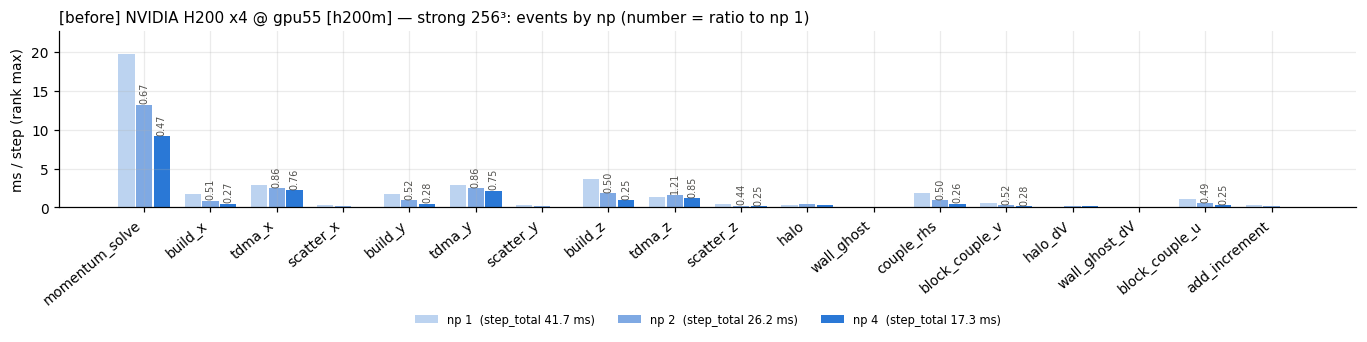

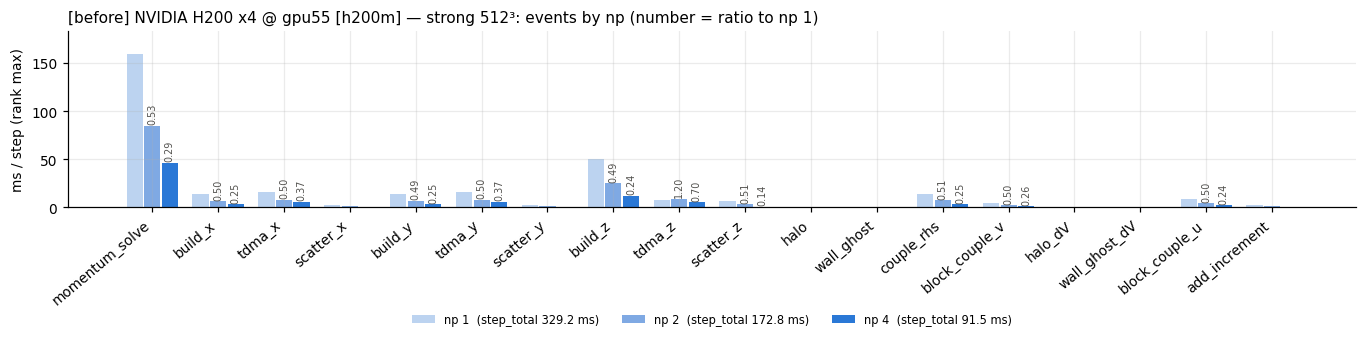

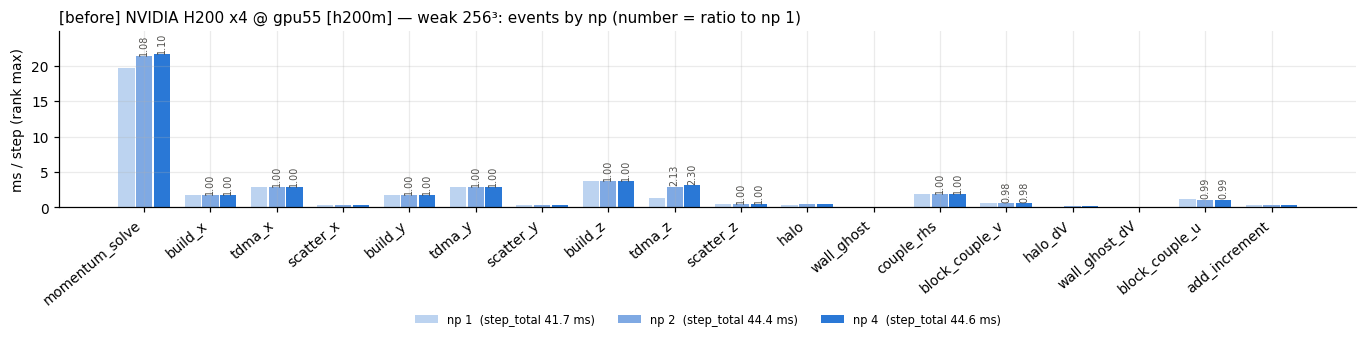

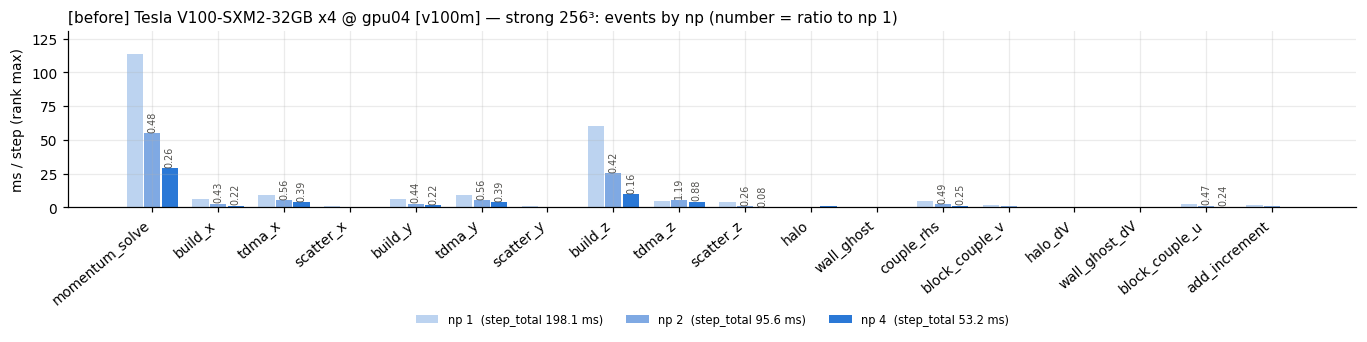

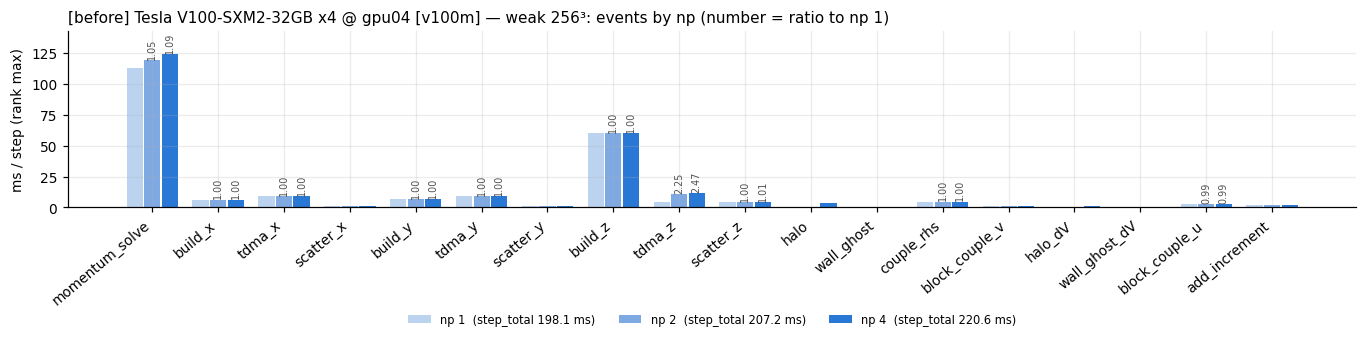

In [ ]:
plot_bars_section(BEFORE, "before")

## B. 최적화 후(최신 바이너리) — 이벤트별 막대

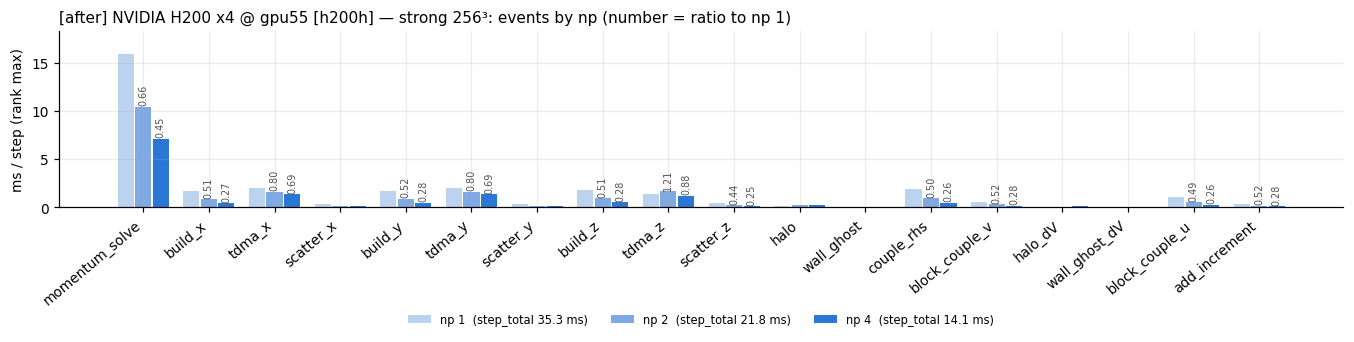

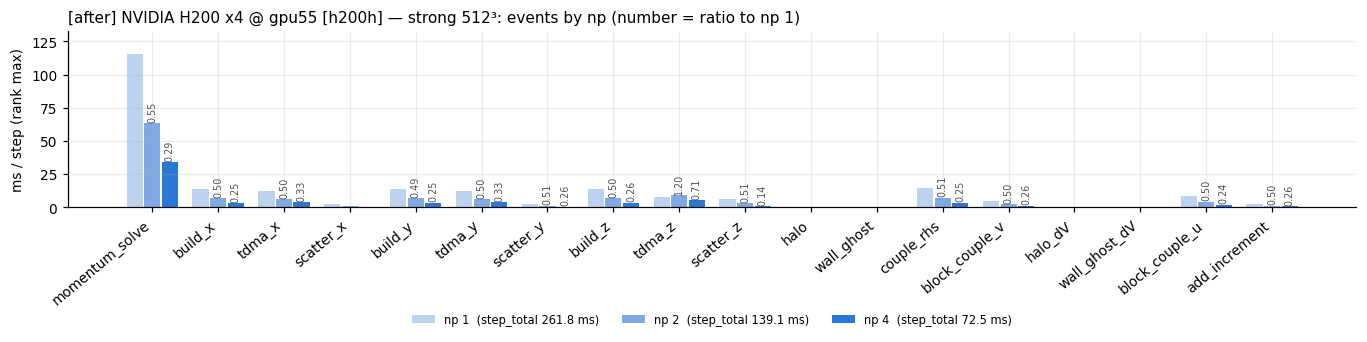

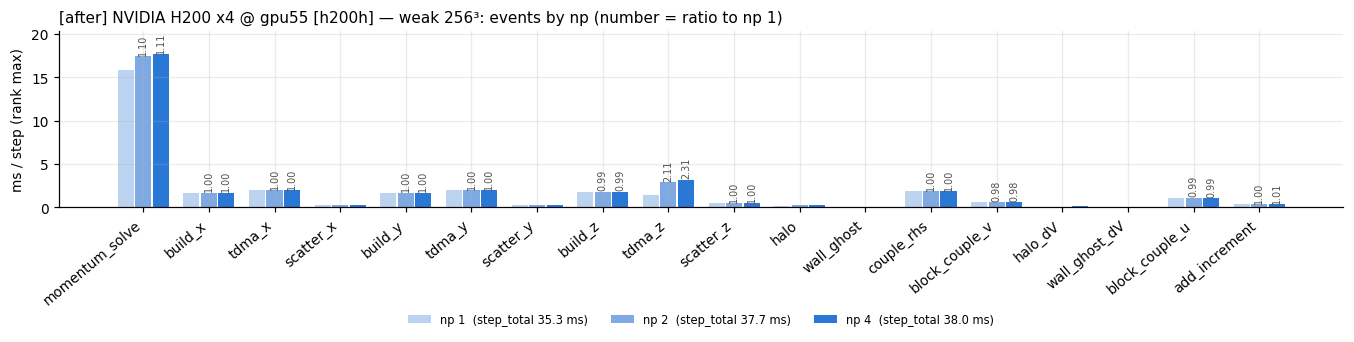

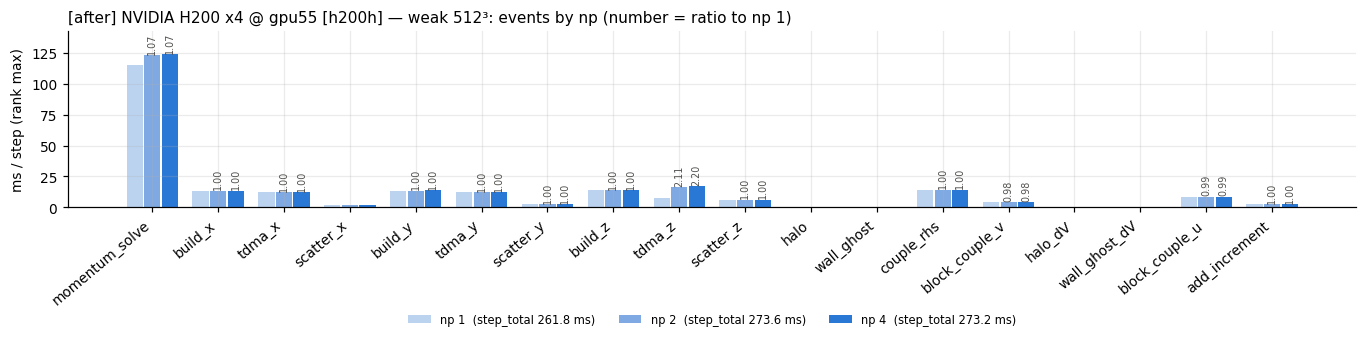

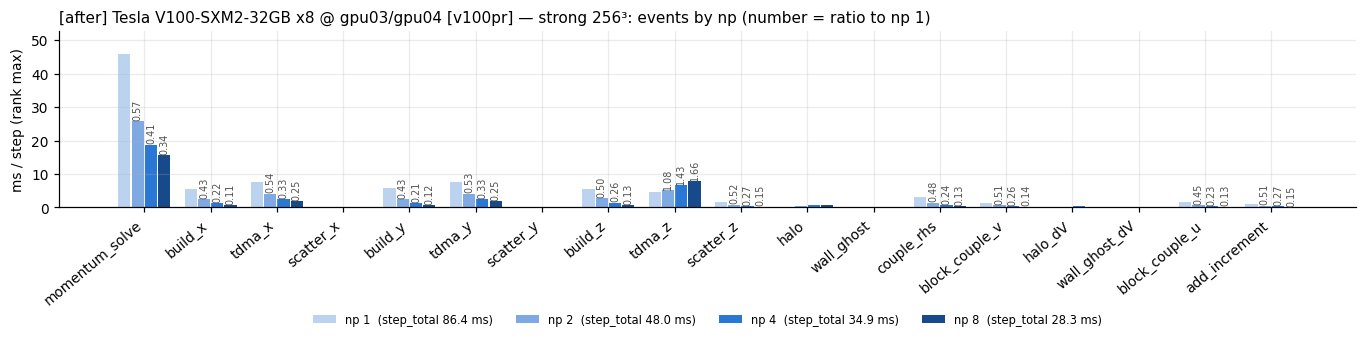

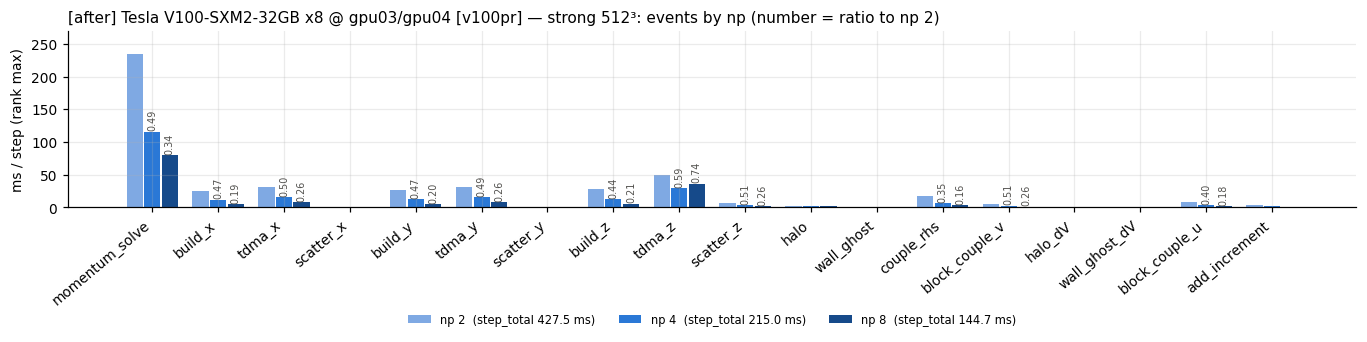

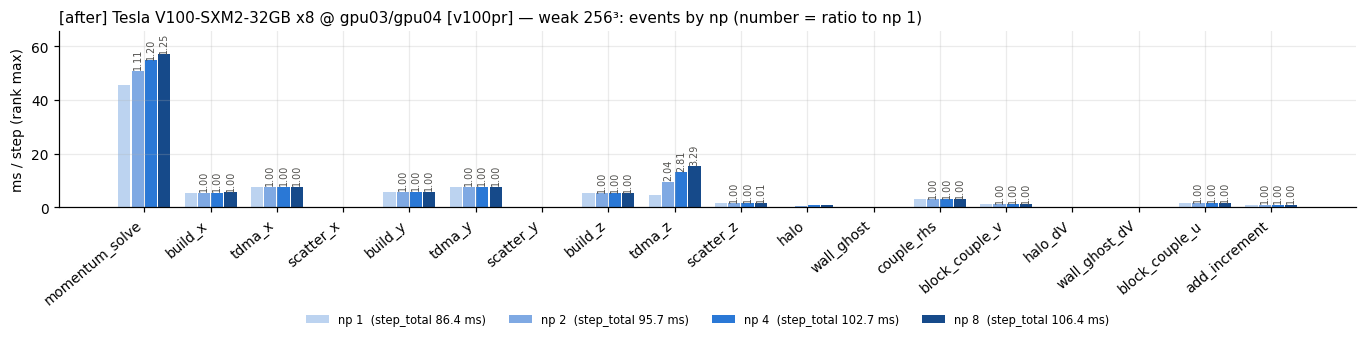

In [ ]:
plot_bars_section(AFTER, "after")

## C. 이벤트별 scaling 곡선 — 최적화 전(○ 파선, 빈 마커)과 후(■ 실선, 채운 마커)를 같은 패널에

색 = 기종, 점선 = 각 선의 이상선(strong $T_{np_0}\,np_0/np$, weak 평평). 전·후가 겹치면 그 이벤트는 바뀌지 않은 것, 벌어지면 그만큼 줄어든 것.

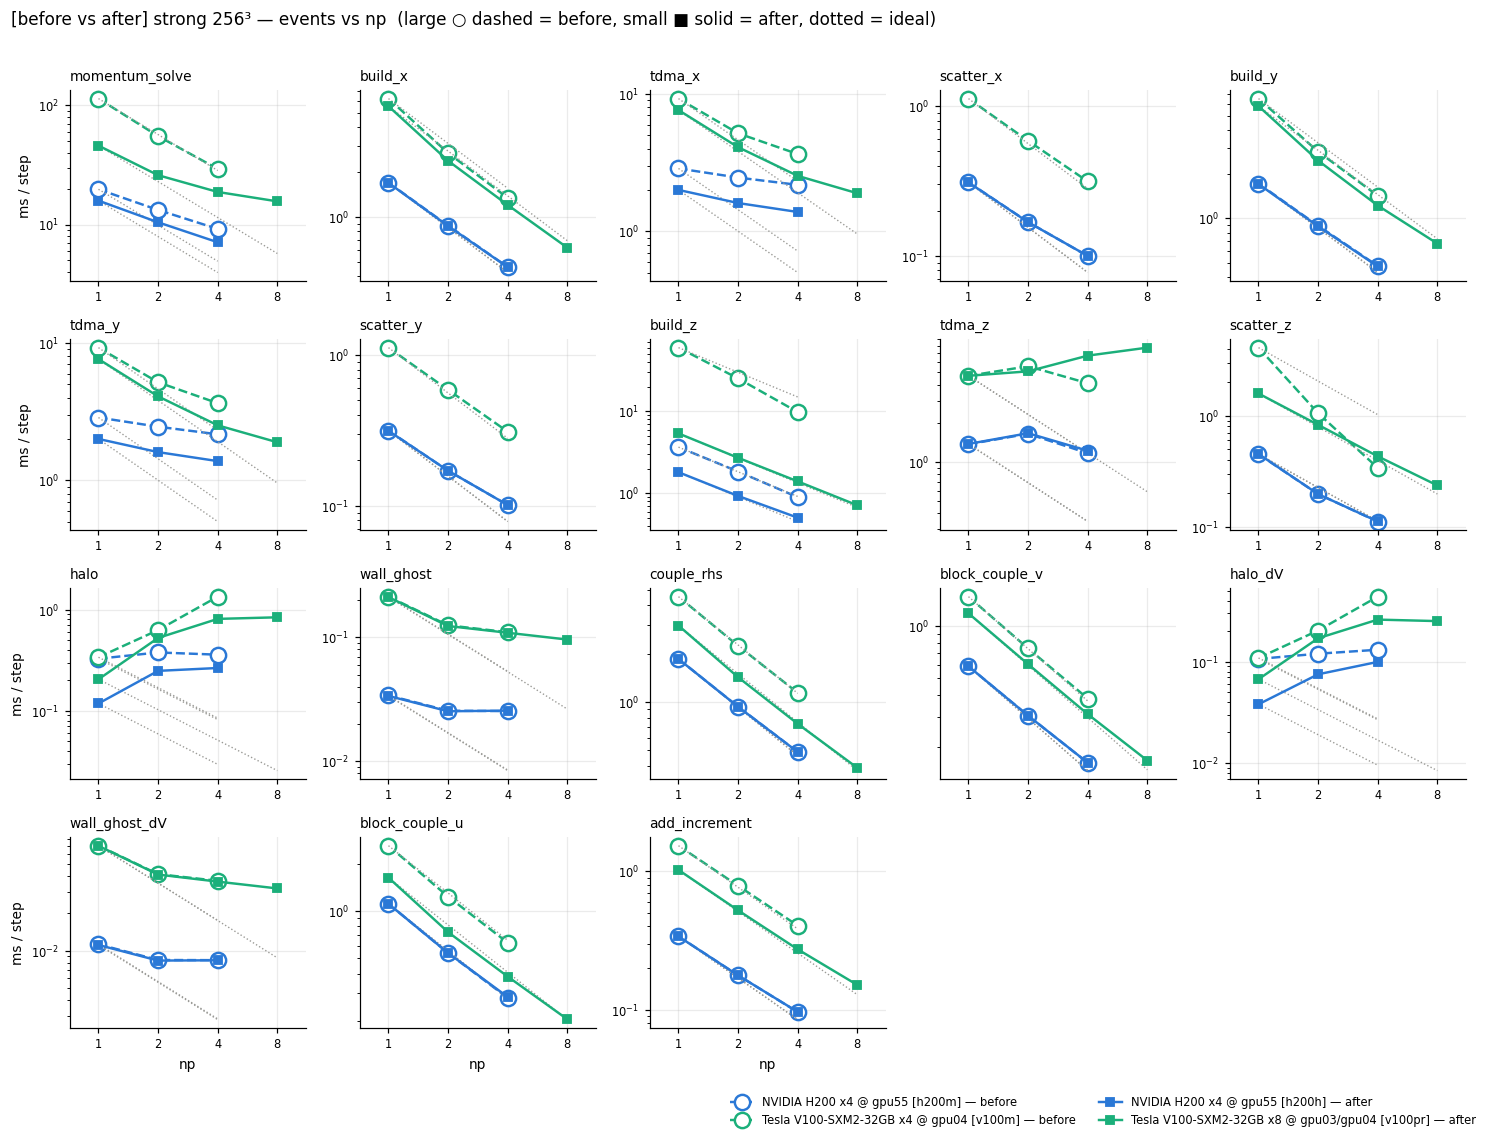

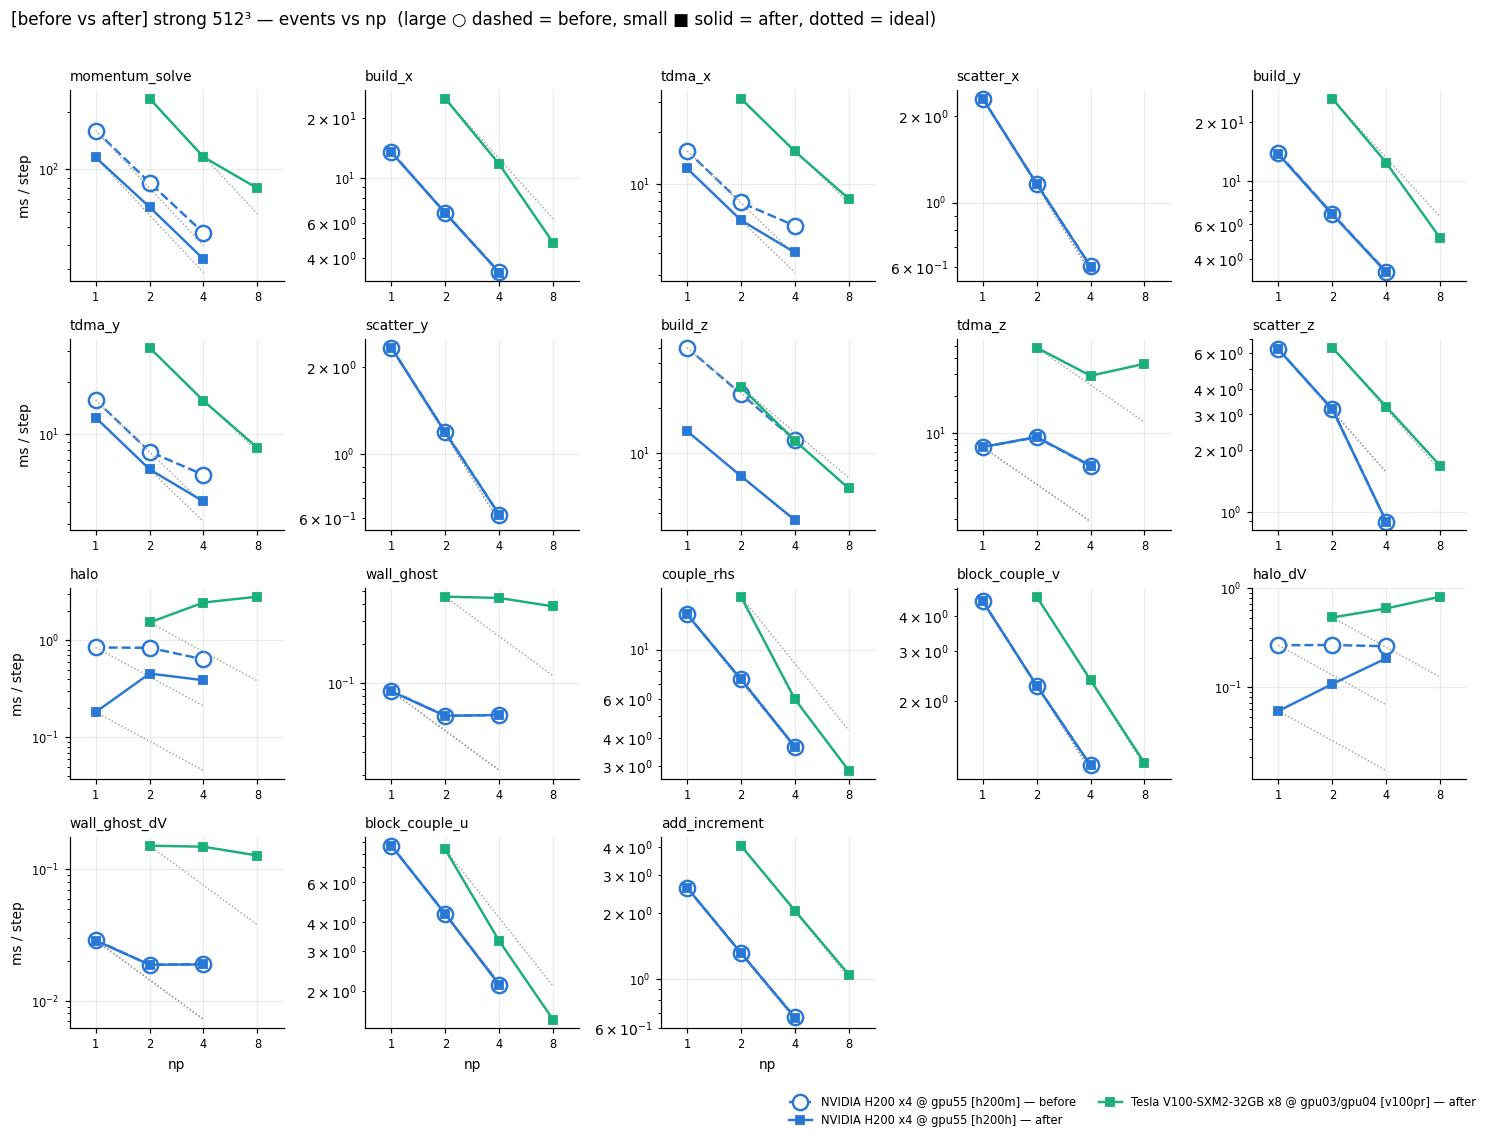

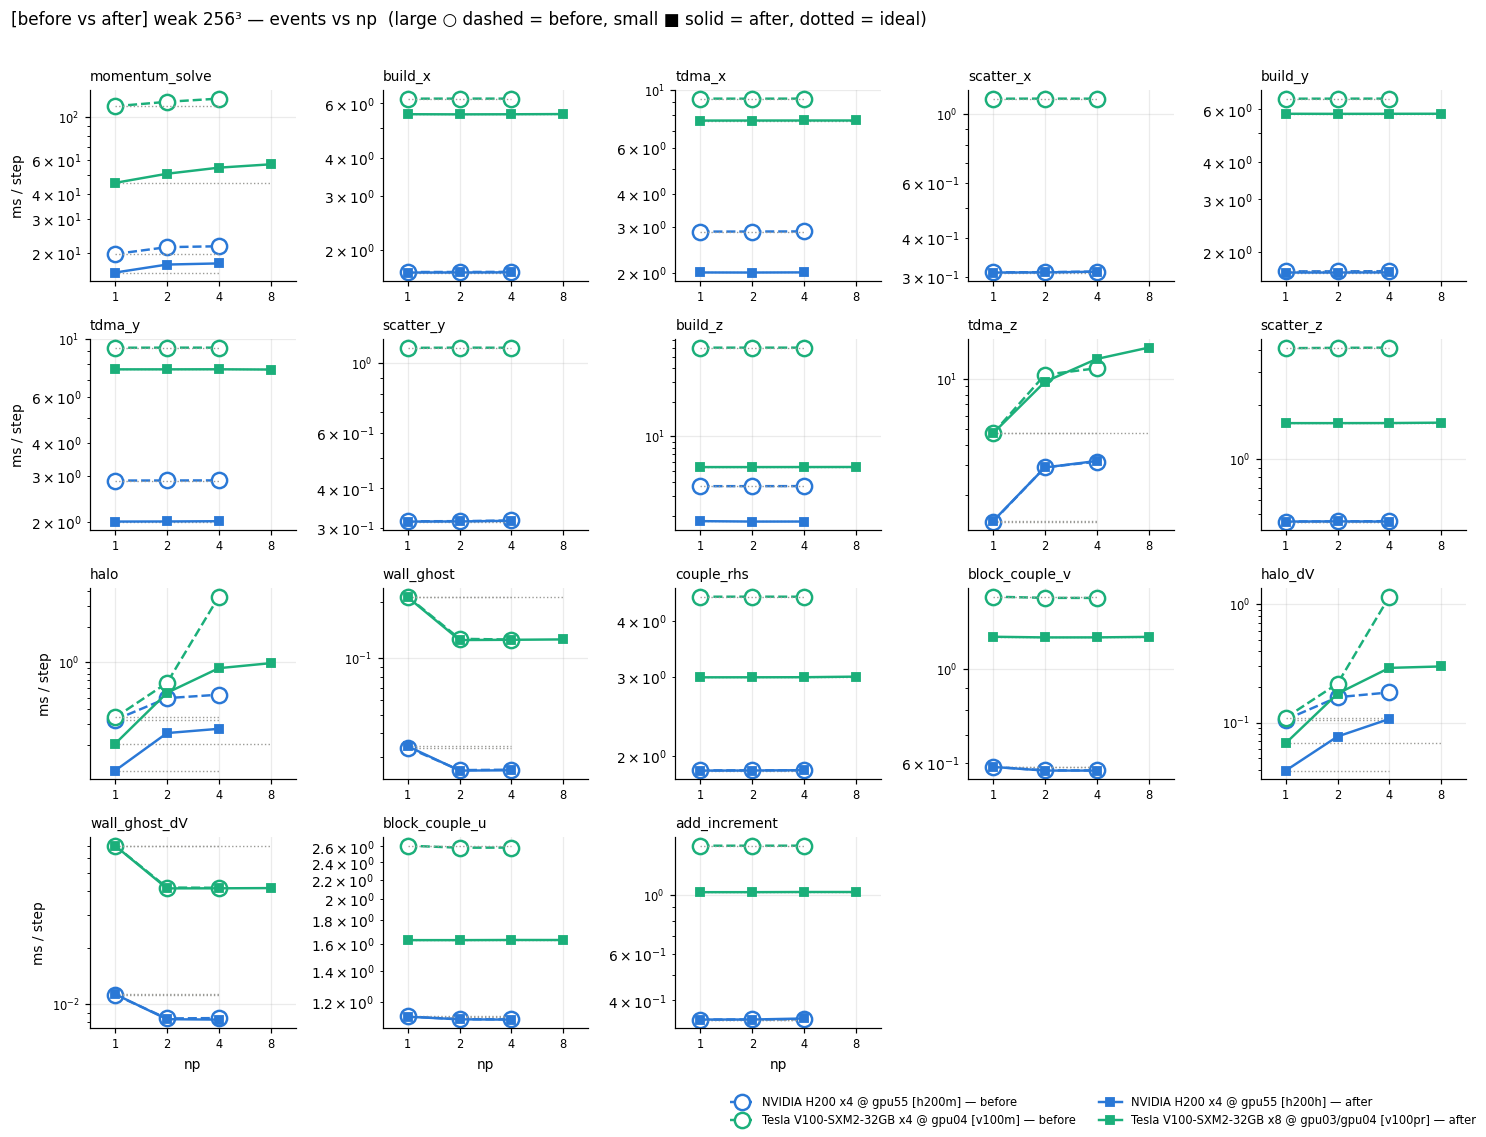

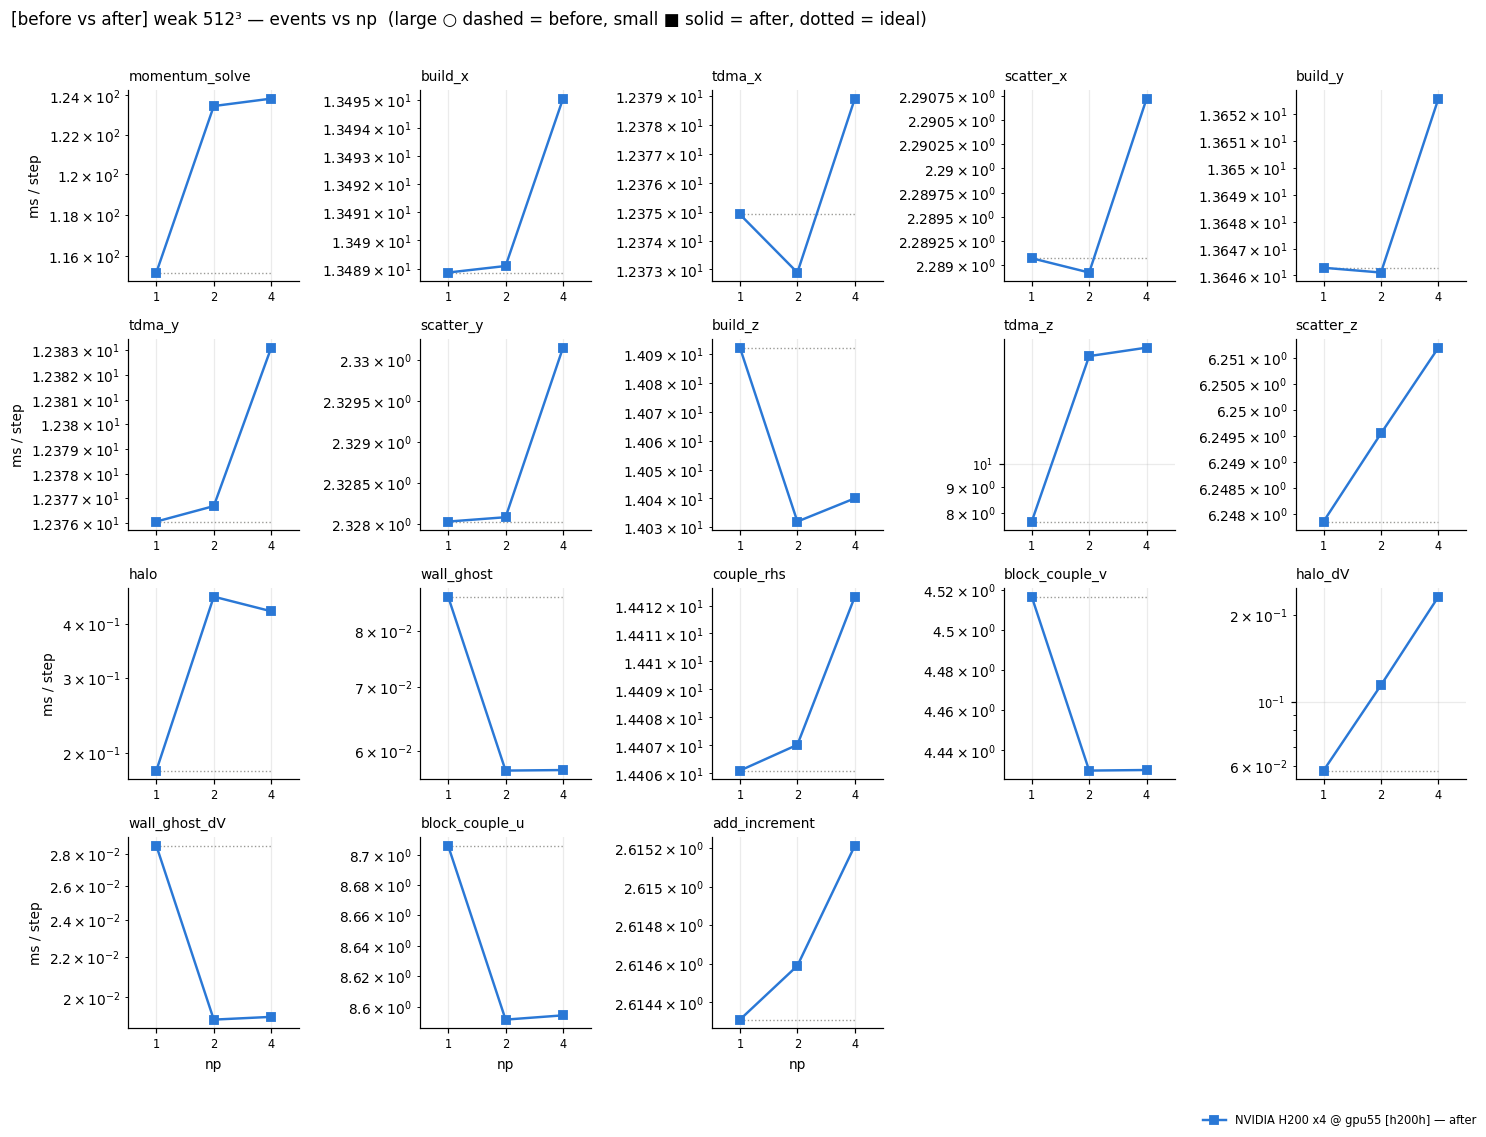

In [ ]:
plot_scaling_section([(BEFORE, "before"), (AFTER, "after")])

## D. 최적화 전 vs 후 — 같은 기종·문제 크기·np 에서 이벤트별 시간과 감소량

왼쪽: 전(회색)·후(파랑) ms/step. 오른쪽: 감소량 = 전 − 후 (ms/step, 양수가 개선), 막대 위 숫자는 감소율 %. 두 바이너리를 같은 노드에서 돈 조합만.

hw    mode   n    np  | step before    after   gain |  momentum_solve    after   gain | 가장 많이 줄어든 이벤트
h200  strong 256  1   |        41.7     35.3    15% |           19.72    15.85    20% | build_z −1.86, tdma_x −0.87, tdma_y −0.87
h200  strong 256  2   |        26.2     21.8    17% |           13.23    10.44    21% | build_z −0.92, tdma_x −0.86, tdma_y −0.85
h200  strong 256  4   |        17.3     14.1    18% |            9.19     7.10    23% | tdma_x −0.80, tdma_y −0.78, build_z −0.39
h200  strong 512  1   |       329.2    261.8    20% |          159.24   115.20    28% | build_z −36.49, tdma_x −3.26, tdma_y −3.25
h200  strong 512  2   |       172.8    139.1    20% |           85.14    63.35    26% | build_z −17.86, tdma_x −1.65, tdma_y −1.65
h200  strong 512  4   |        91.5     72.5    21% |           46.37    33.84    27% | build_z −8.68, tdma_x −1.72, tdma_y −1.72
h200  weak   256  1   |        41.7     35.3    15% |           19.73    15.85    20% | build_z −1.86, tdma_y −0.87,

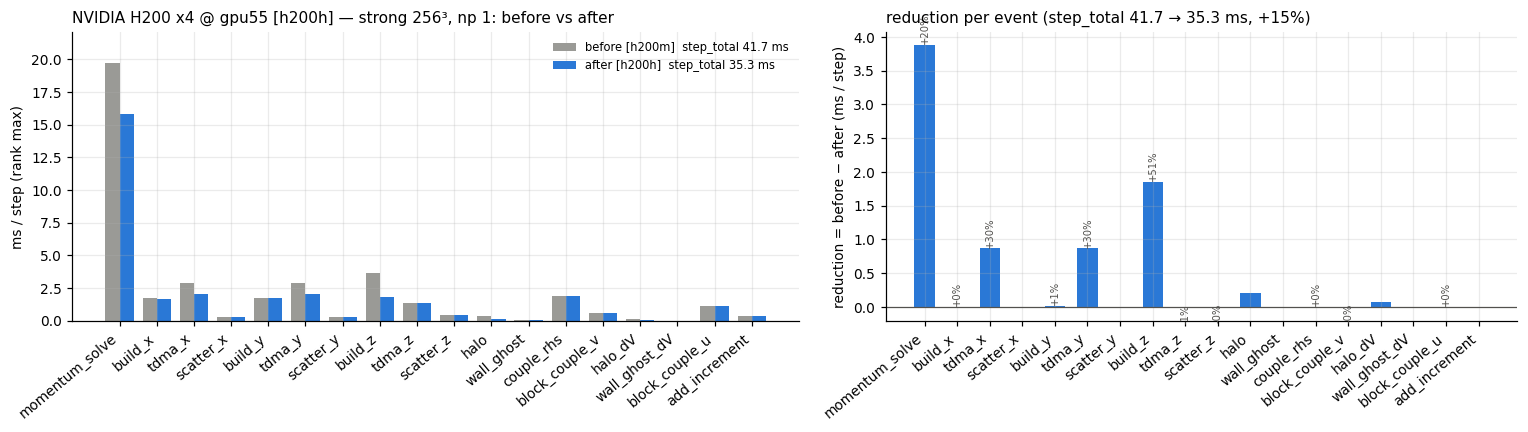

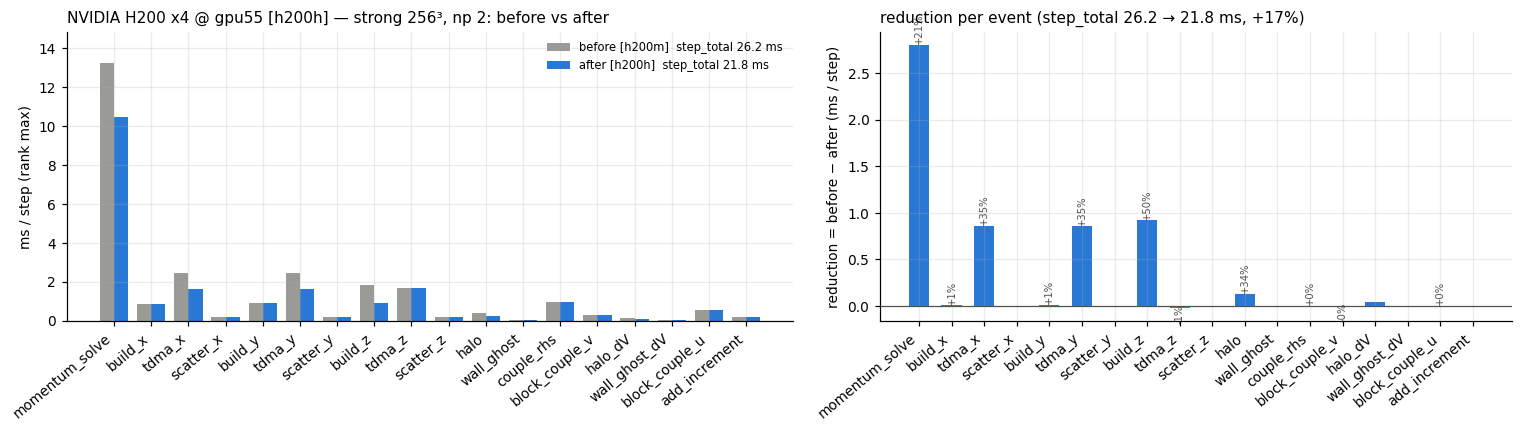

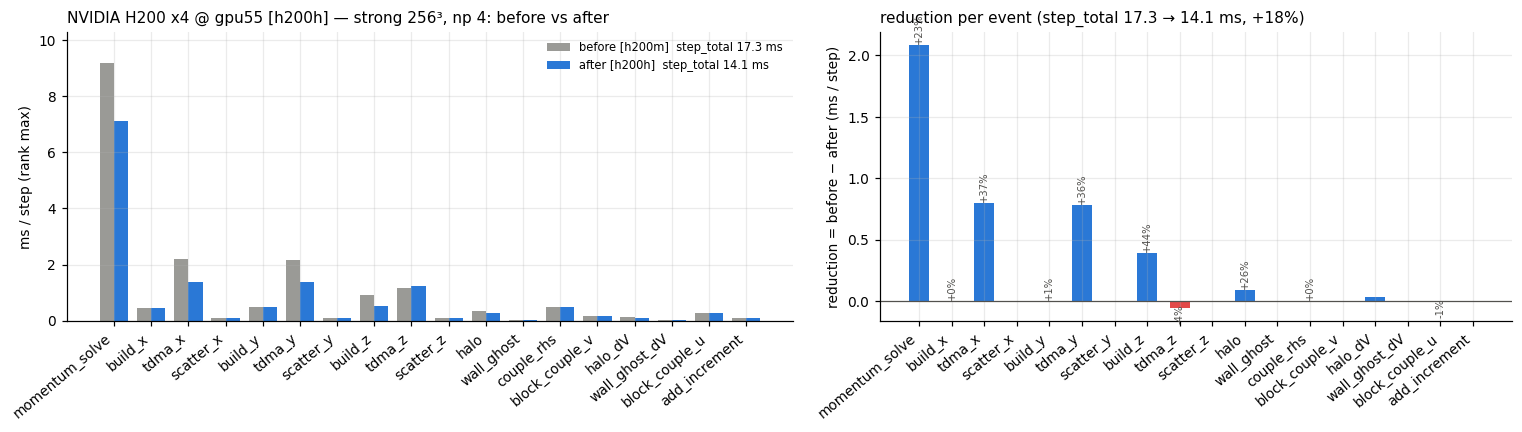

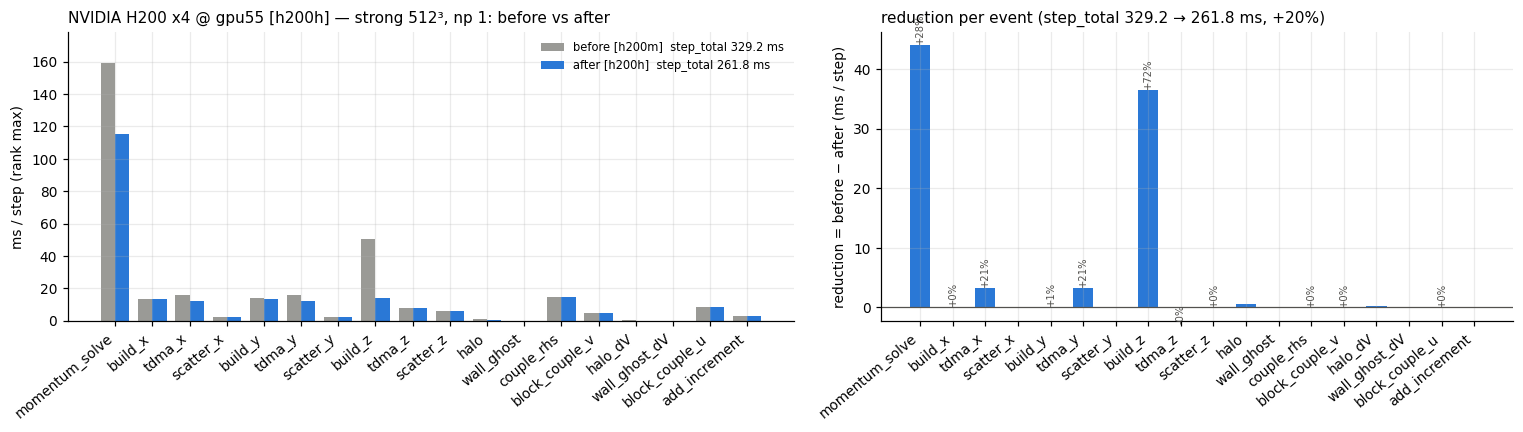

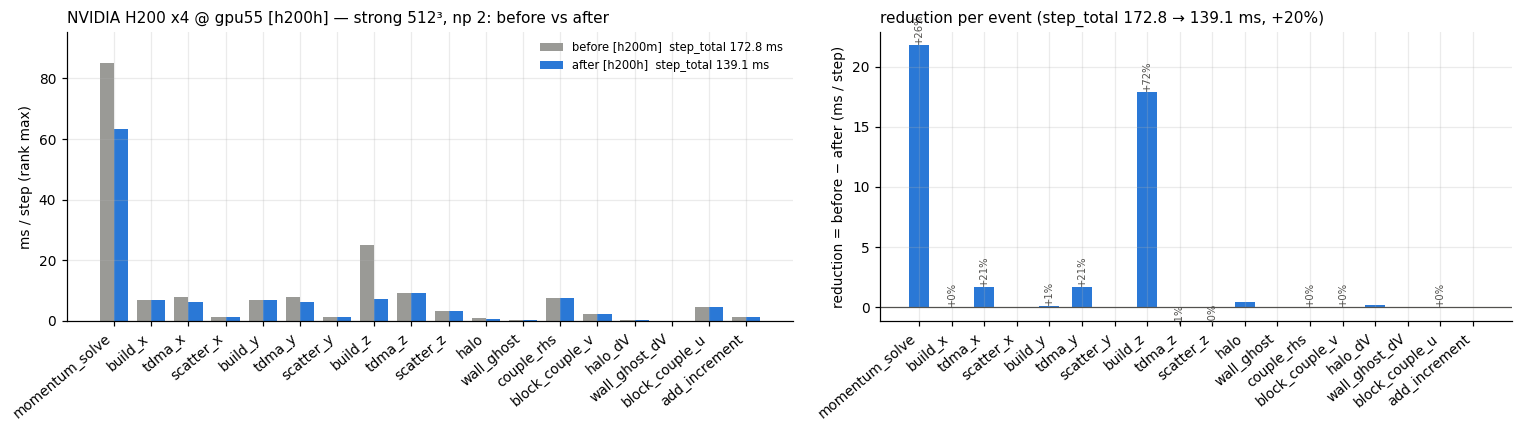

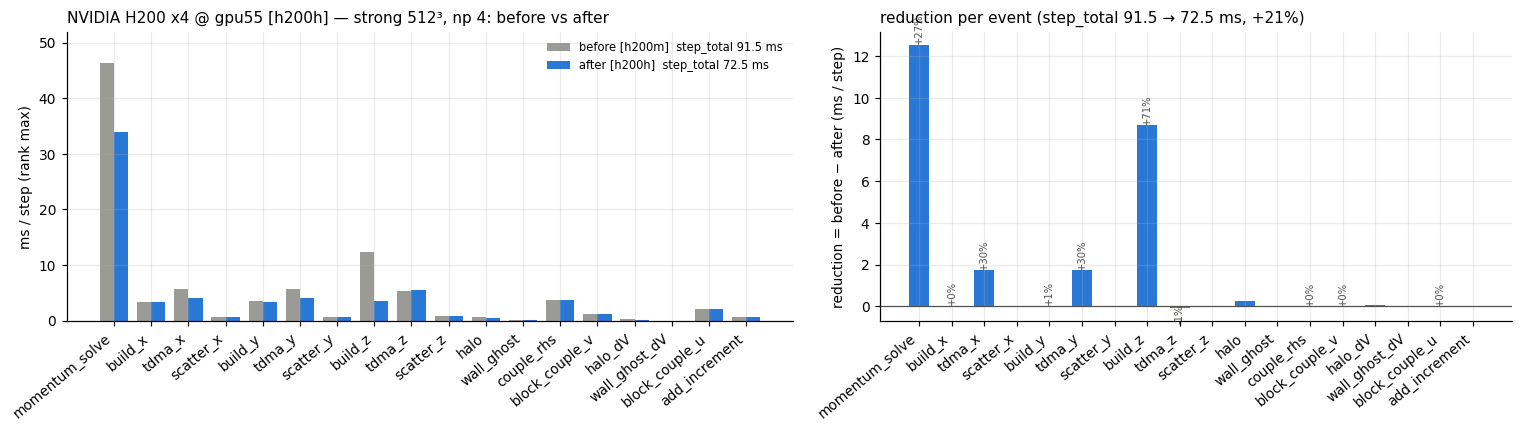

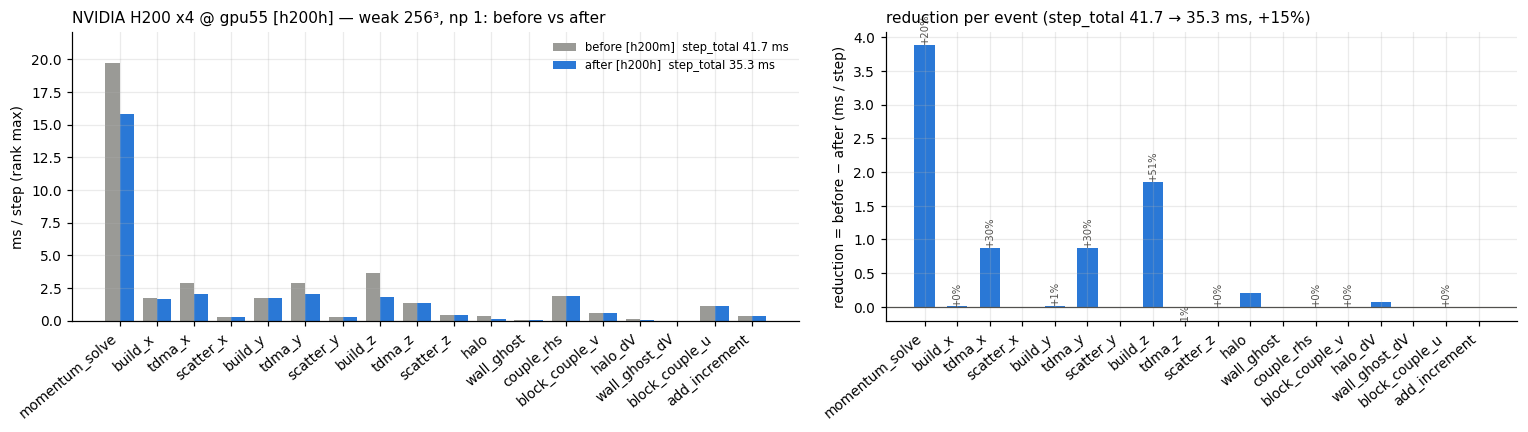

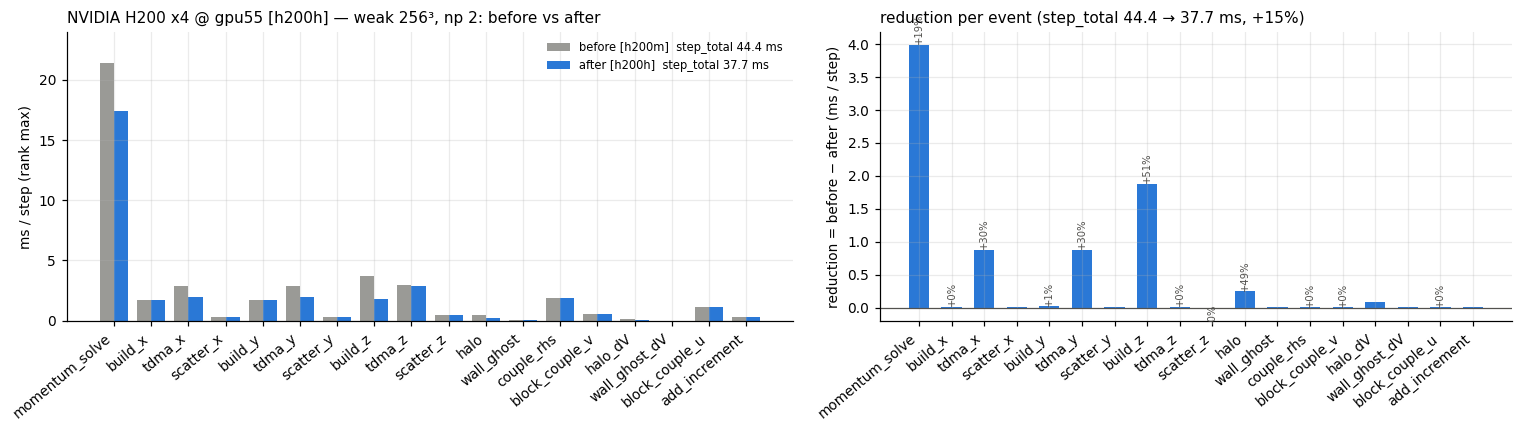

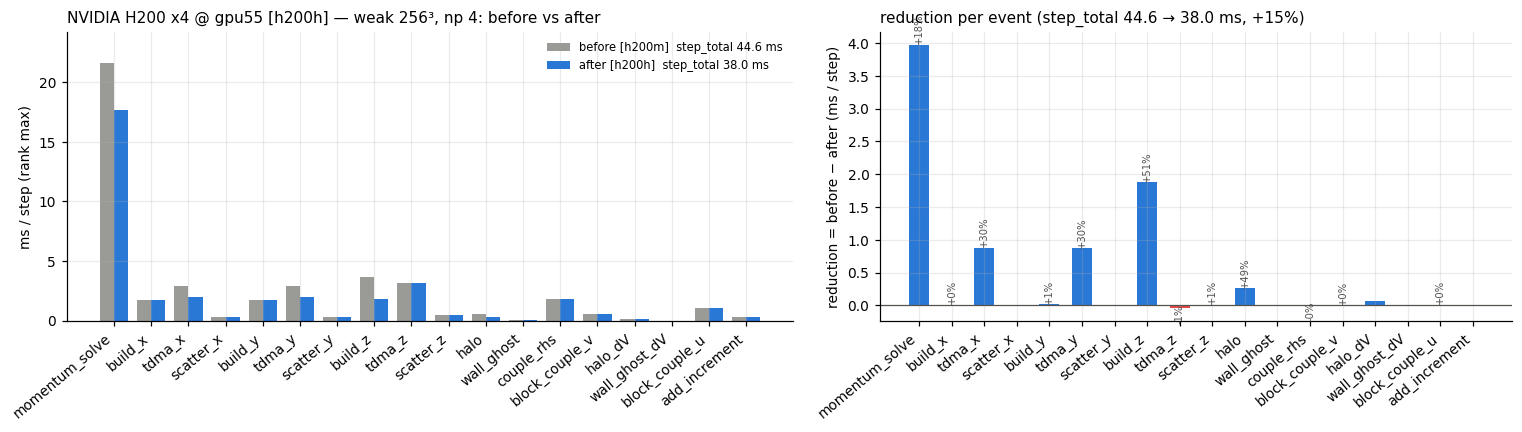

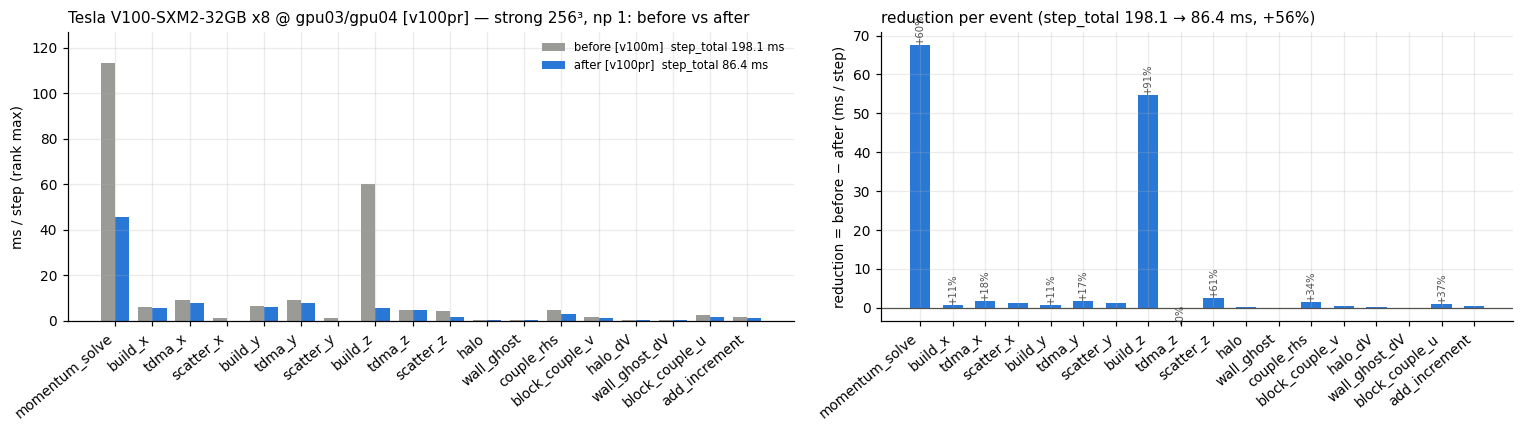

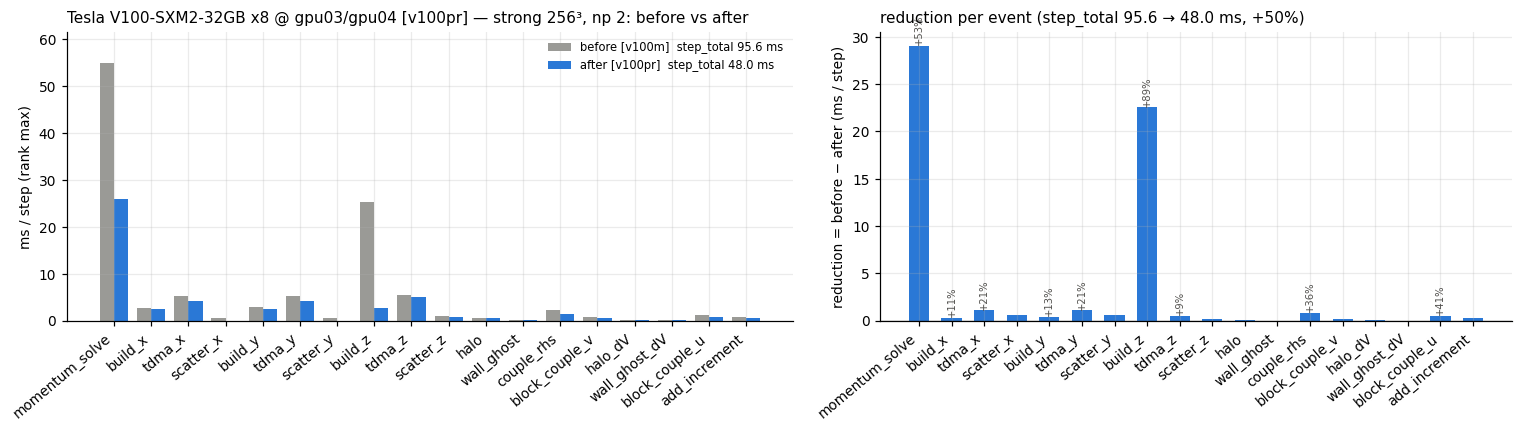

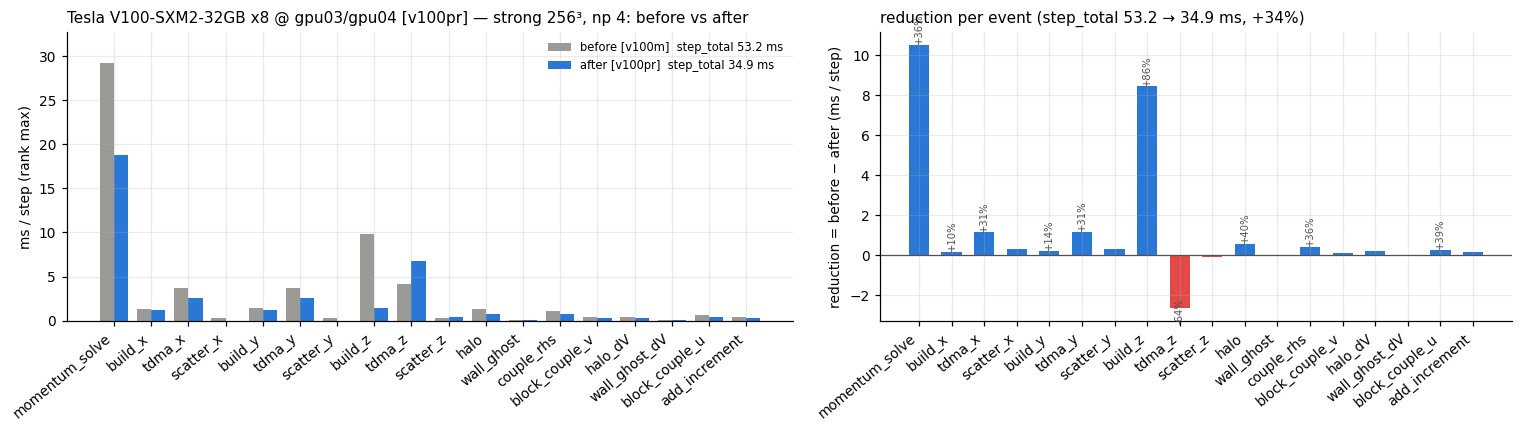

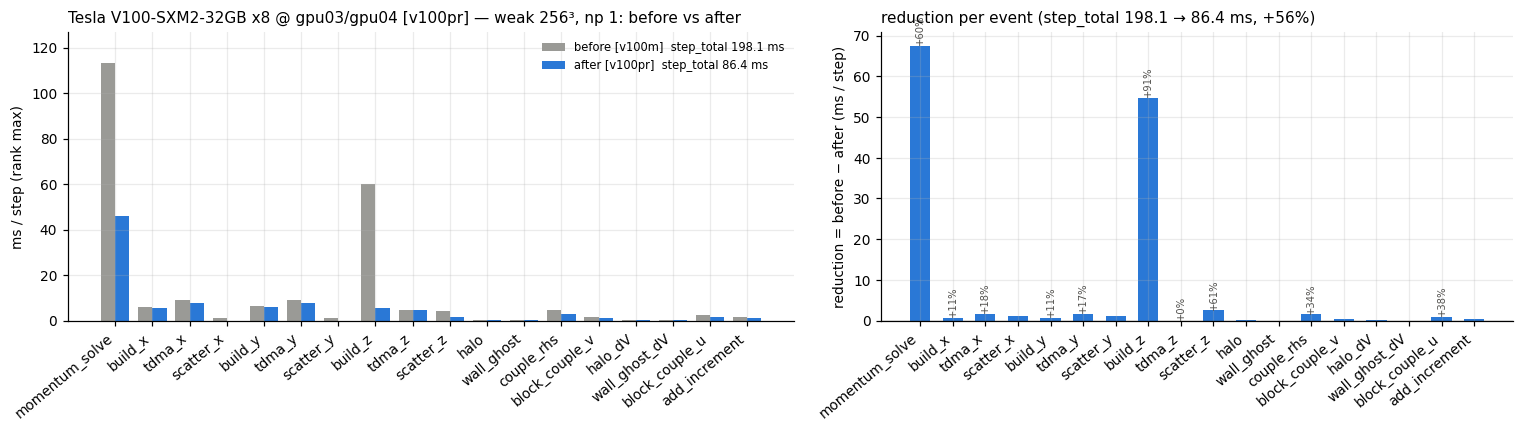

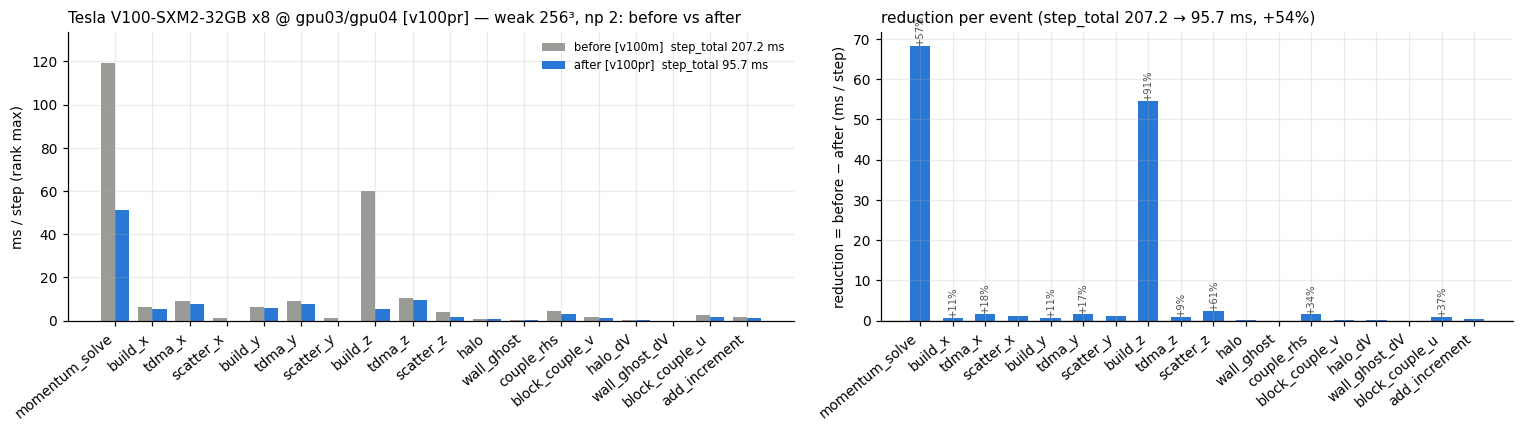

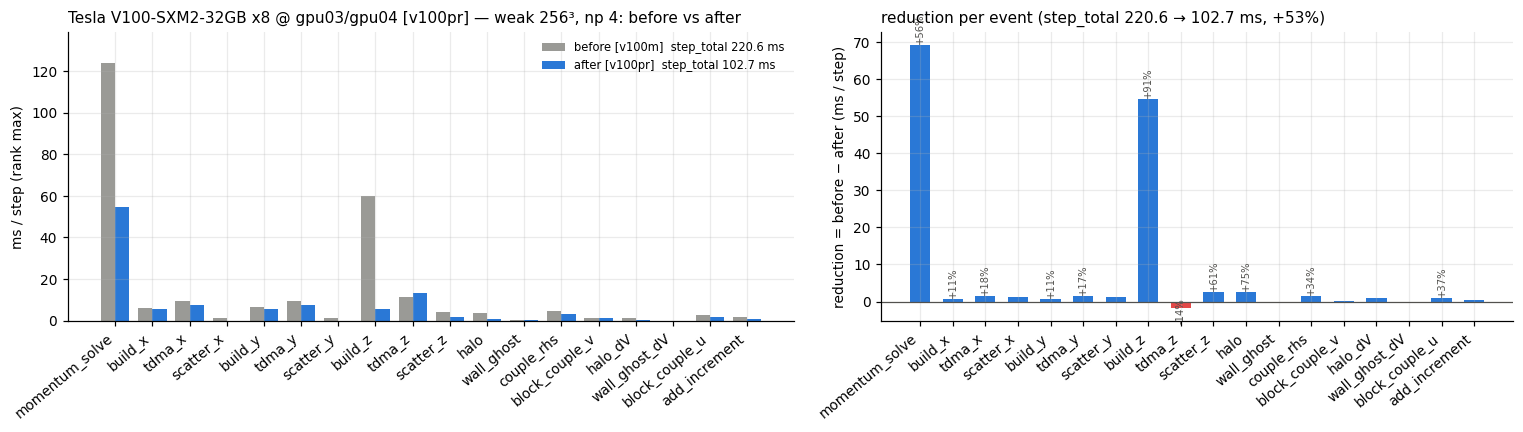

In [ ]:
def plot_before_after(mode, hw, n, np_):
    kb, ka = (hw, mode, n, np_), (hw, mode, n, np_)
    if kb not in BEFORE or ka not in AFTER:
        return
    b, a = BEFORE[kb], AFTER[ka]
    vb = np.array([event_time(b, e) for e in EVENTS]); va = np.array([event_time(a, e) for e in EVENTS])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.0), gridspec_kw={"width_ratios": [1.15, 1]})
    xs = np.arange(len(EVENTS)); w = 0.38
    ax1.bar(xs - w / 2, vb, w, color="#9a9a96", label=f"before [{BEFORE_TAG[kb]}]  step_total {b['step_total']:.1f} ms")
    ax1.bar(xs + w / 2, va, w, color="#2a78d6", label=f"after [{AFTER_TAG[ka]}]  step_total {a['step_total']:.1f} ms")
    ax1.set_xticks(xs); ax1.set_xticklabels(EVENTS, rotation=40, ha="right"); ax1.set_ylabel("ms / step (rank max)")
    ax1.set_title(f"{hw_desc('after', hw)} — {mode} {n}³, np {np_}: before vs after", fontsize=10, loc="left")
    ax1.set_ylim(0, max(vb.max(), va.max()) * 1.12); ax1.legend(frameon=False, fontsize=7.5)
    d = vb - va
    colors = ["#2a78d6" if v >= 0 else "#e34948" for v in d]
    ax2.bar(xs, d, 0.62, color=colors)
    for x, v, bv in zip(xs, d, vb):
        if bv > 0.02 * vb.max():
            ax2.annotate(f"{100 * v / bv:+.0f}%", (x, v), xytext=(0, 2 if v >= 0 else -9), textcoords="offset points", ha="center", fontsize=6.5, color="#52514e", rotation=90)
    ax2.axhline(0, color="#52514e", lw=0.8)
    ax2.set_xticks(xs); ax2.set_xticklabels(EVENTS, rotation=40, ha="right"); ax2.set_ylabel("reduction = before − after (ms / step)")
    ax2.set_title(f"reduction per event (step_total {b['step_total']:.1f} → {a['step_total']:.1f} ms, {100*(1-a['step_total']/b['step_total']):+.0f}%)", fontsize=10, loc="left")
    fig.tight_layout()

for hw in ("h200", "v100", "a100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                plot_before_after(mode, hw, n, np_)
plt.show()

# 요약표
print(f"{'hw':5s} {'mode':6s} {'n':4s} {'np':3s} | {'step before':>11s} {'after':>8s} {'gain':>6s} | {TOTAL:>15s} {'after':>8s} {'gain':>6s} | 가장 많이 줄어든 이벤트")
for hw in ("h200", "v100", "a100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                k = (hw, mode, n, np_)
                if k not in BEFORE or k not in AFTER:
                    continue
                b, a = BEFORE[k], AFTER[k]
                d = sorted(((event_time(b, e) - event_time(a, e), e) for e in EVENTS if e != TOTAL), reverse=True)[:3]
                tb, ta = event_time(b, TOTAL), event_time(a, TOTAL)
                print(f"{hw:5s} {mode:6s} {n:<4d} {np_:<3d} | {b['step_total']:11.1f} {a['step_total']:8.1f} {100*(1-a['step_total']/b['step_total']):5.0f}% | "
                      f"{tb:15.2f} {ta:8.2f} {100*(1-ta/tb) if tb>0 else 0:5.0f}% | " + ", ".join(f"{e} −{v:.2f}" for v, e in d))

## E. 조립·커플링 스텐실 역수 직전 vs 최종 — V100

전 = `v100r1`(momentum_rhs 까지), 후 = `v100s`(sweep_band·own_face_blend·couple_* 의 나눗셈을 역수 곱으로). 차이는 build_x/y/z·couple_rhs·block_couple_* 에서만 나야 한다.

hw    mode   n    np  |  momentum_solve before    after   gain | build_x+y+z (3성분 합) 전 → 후 | couple_rhs+block_couple 전 → 후 | tdma_x+y+z (3성분 합) 전 → 후
v100  strong 256  1   |                   56.1     45.8    18% |   18.91 →   16.72 ms |    8.62 →    5.81 ms |   20.03 →   20.00 ms
v100  strong 256  2   |                   30.0     25.9    14% |    8.60 →    7.57 ms |    4.23 →    2.77 ms |   13.33 →   13.28 ms
v100  strong 256  4   |                   17.9     18.7    -5% |    4.39 →    3.82 ms |    2.15 →    1.43 ms |    9.14 →   11.79 ms
v100  strong 256  8   |                   16.5     15.6     5% |    2.30 →    2.01 ms |    1.14 →    0.76 ms |   11.48 →   11.56 ms
v100  strong 512  2   |                  277.0    233.9    16% |   86.66 →   78.81 ms |   40.19 →   30.38 ms |  111.70 →  111.68 ms
v100  strong 512  4   |                  132.9    115.8    13% |   40.71 →   36.30 ms |   16.75 →   11.66 ms |   60.05 →   60.01 ms
v100  strong 512  8   |                   86.3     79.5   

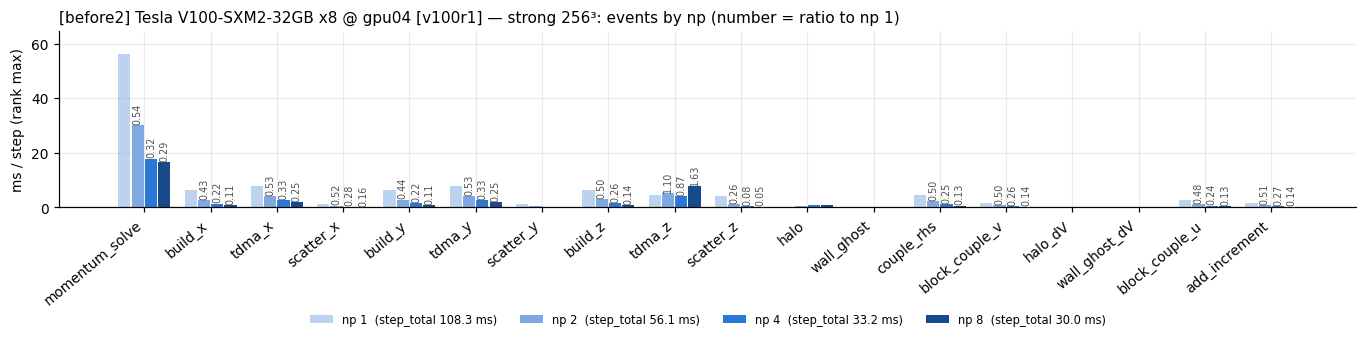

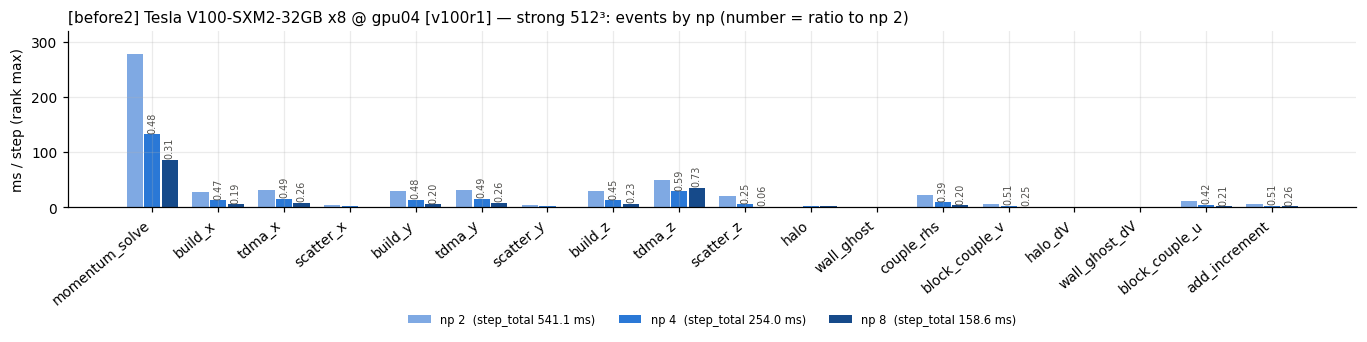

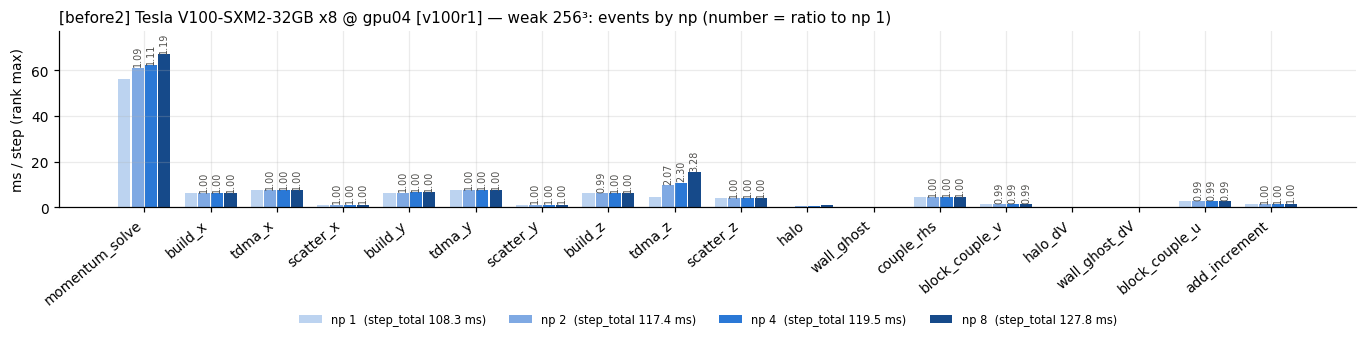

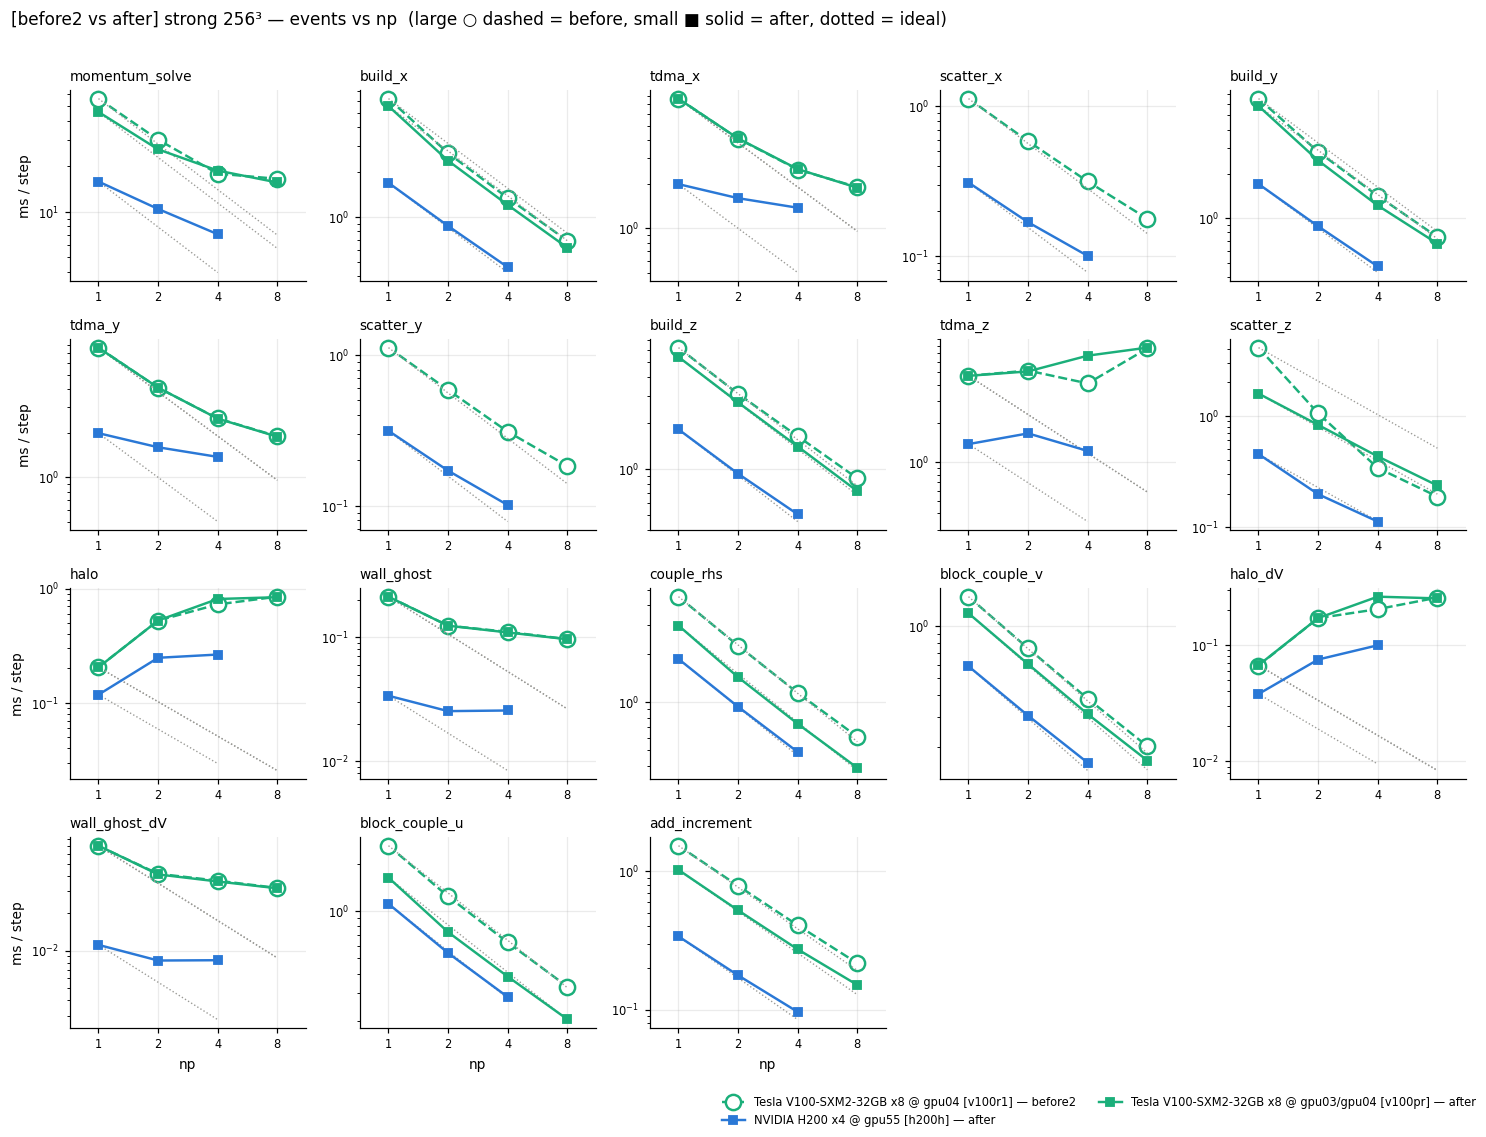

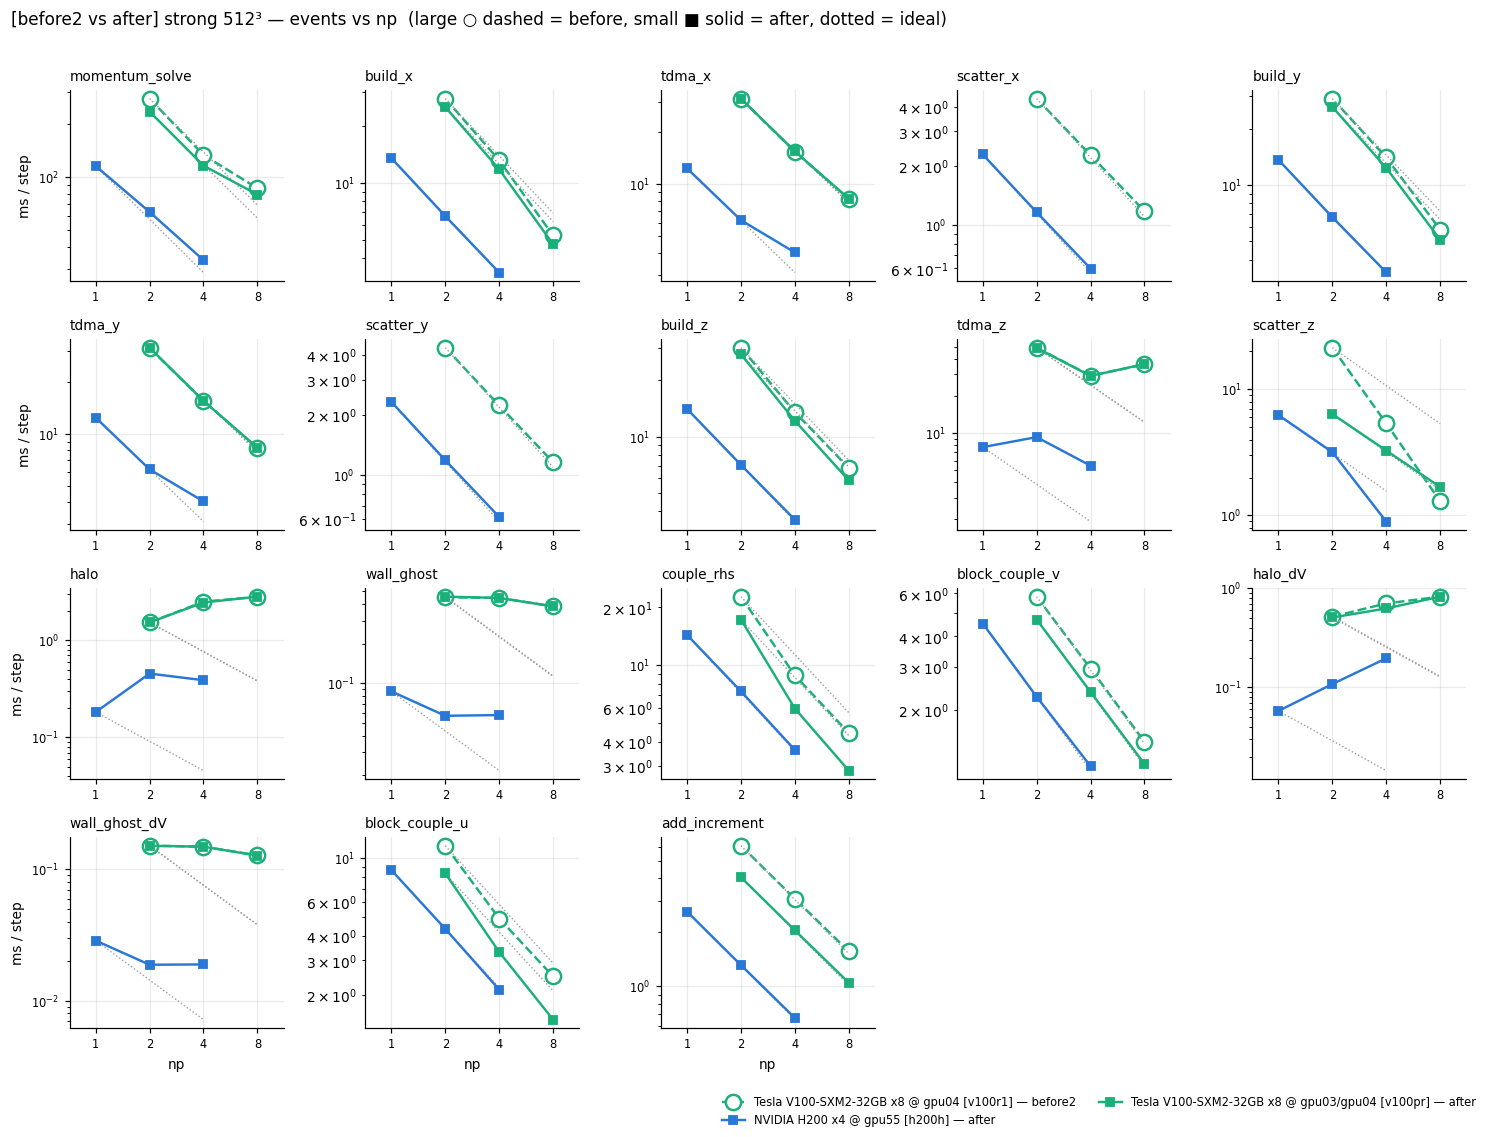

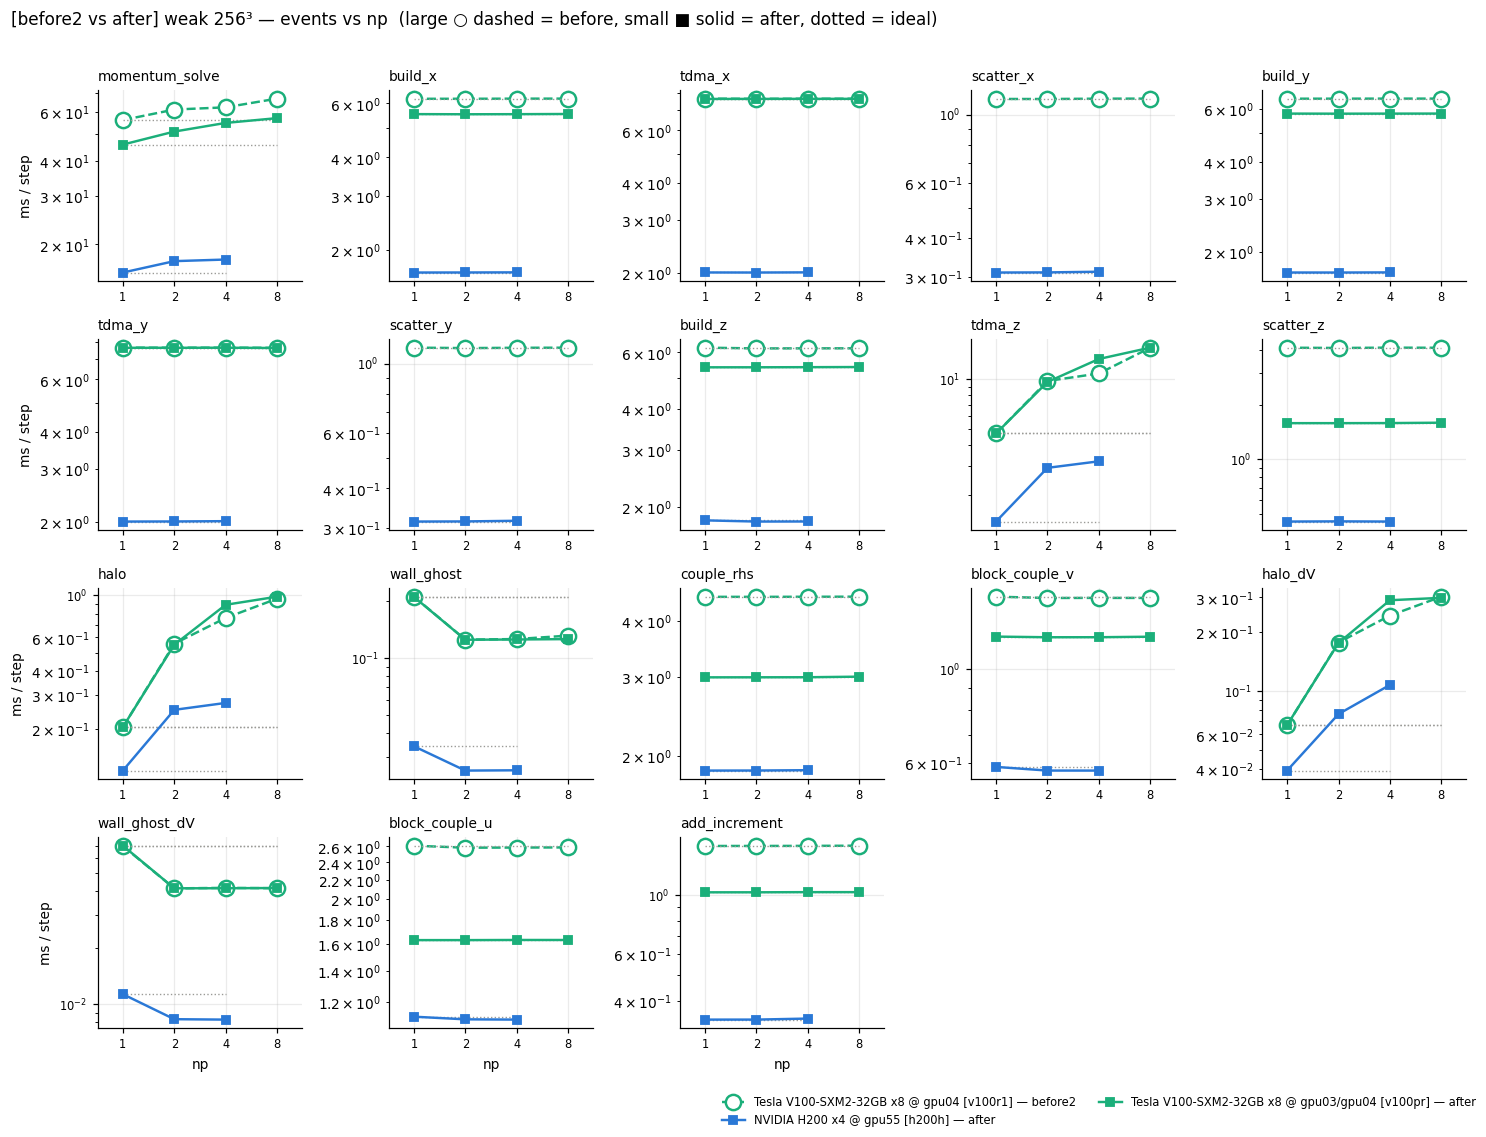

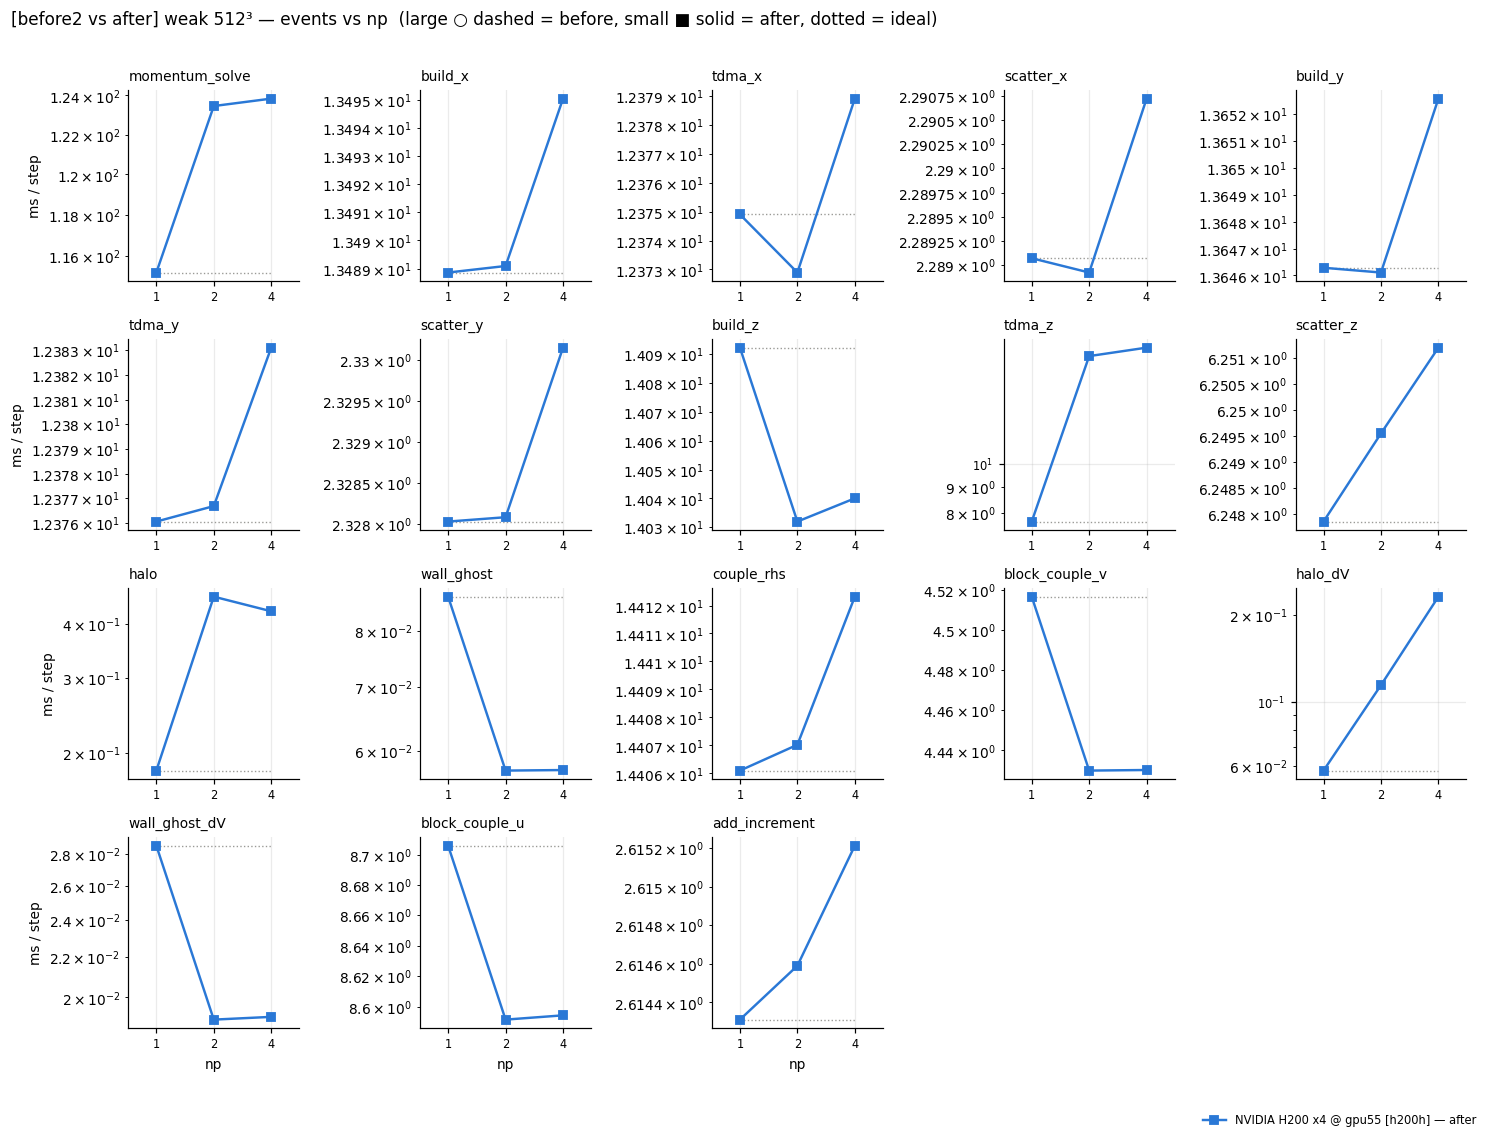

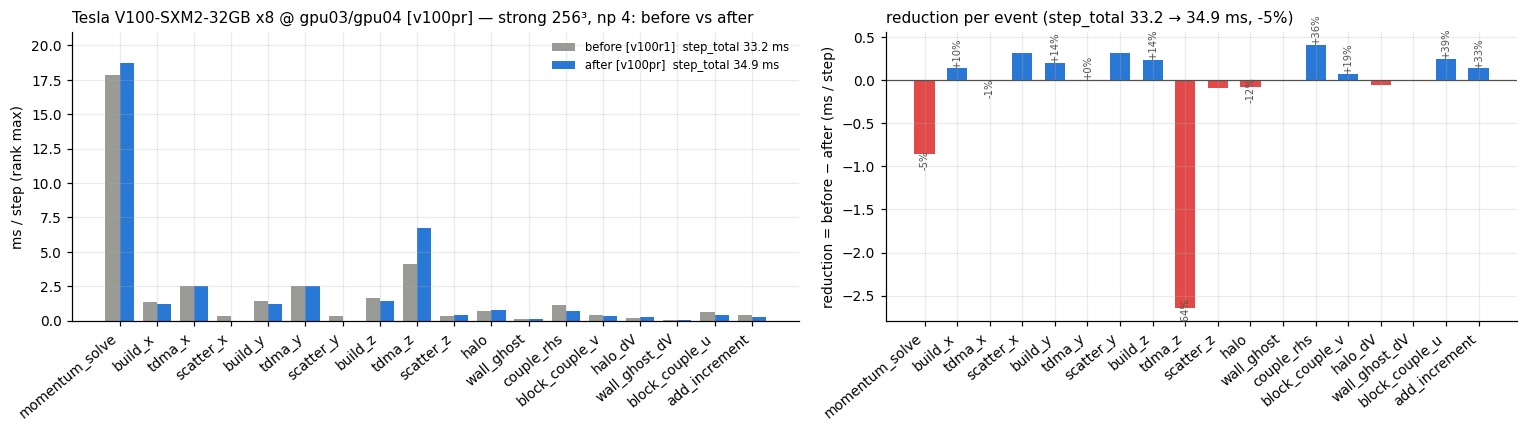

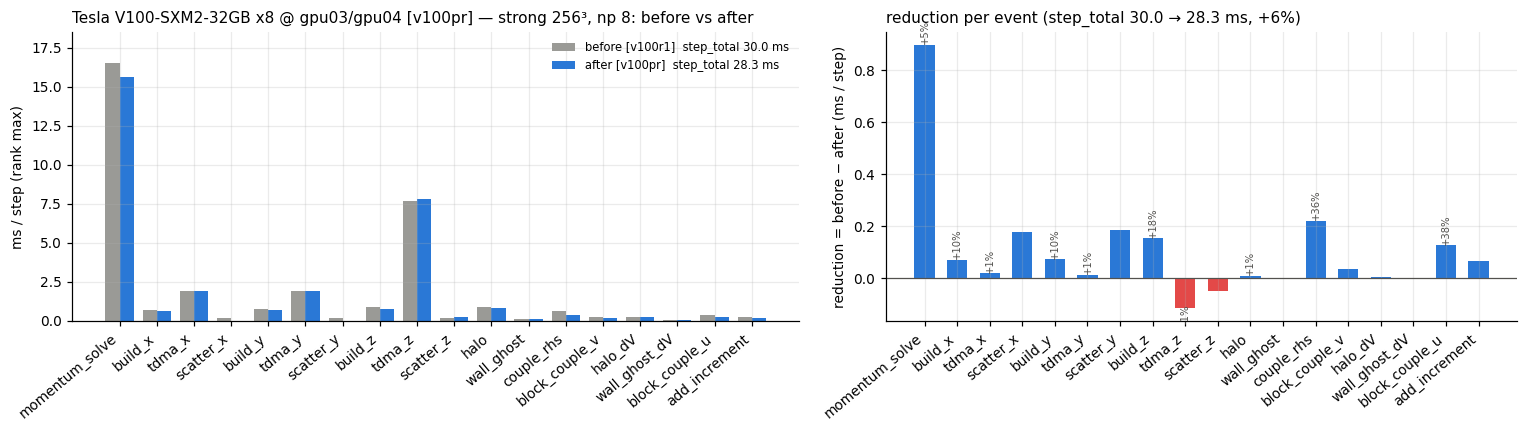

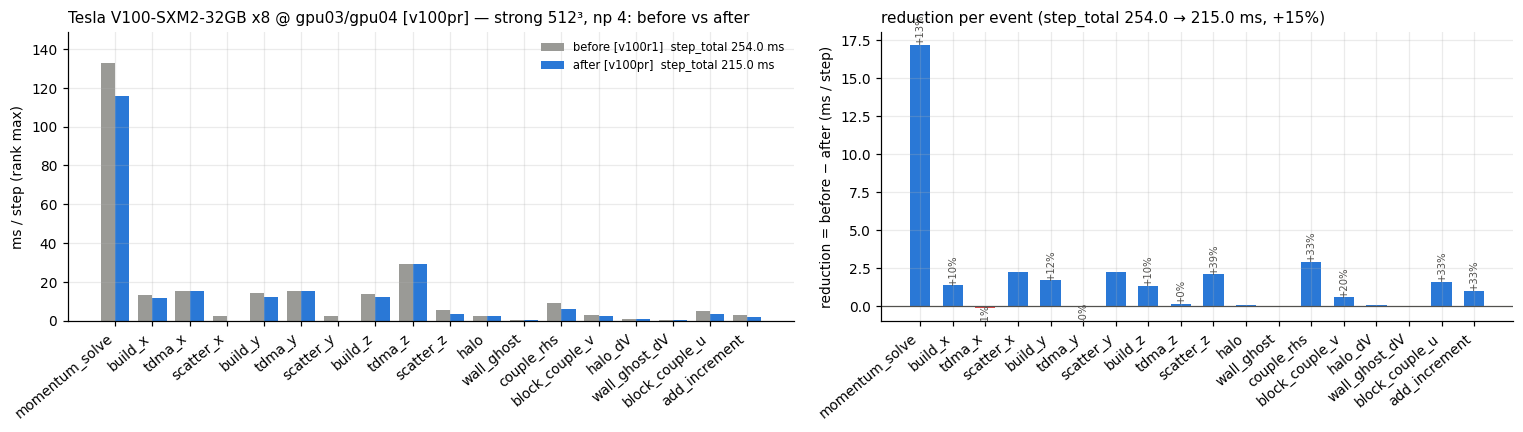

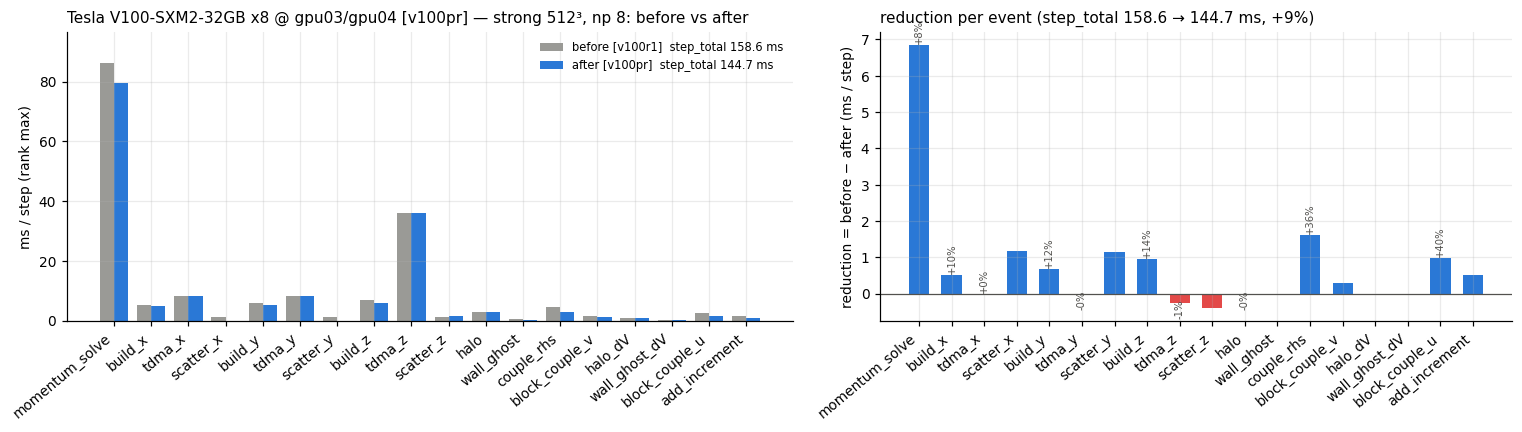

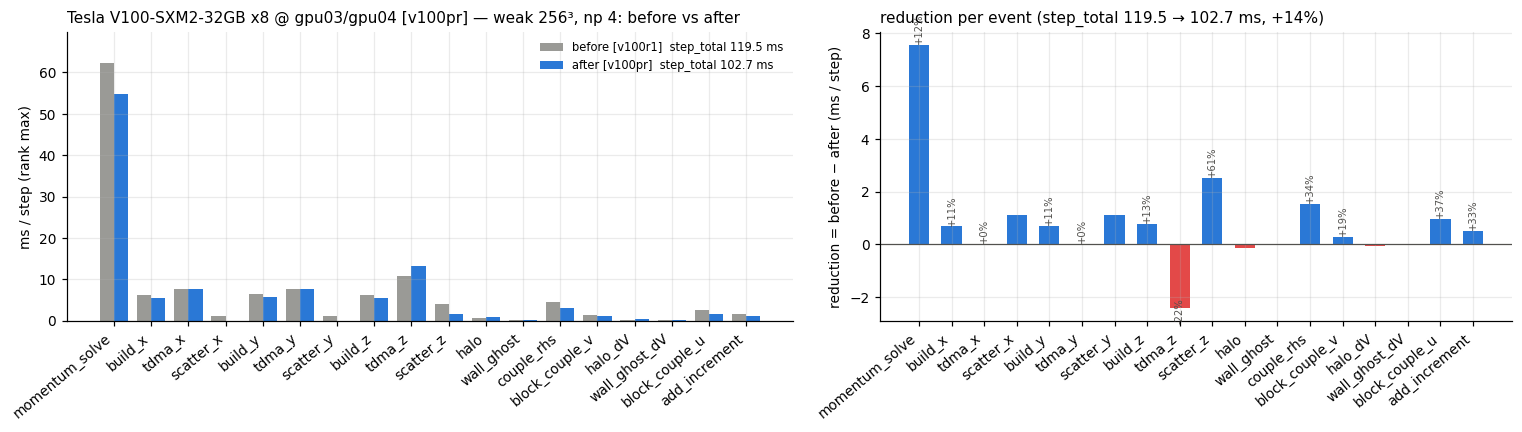

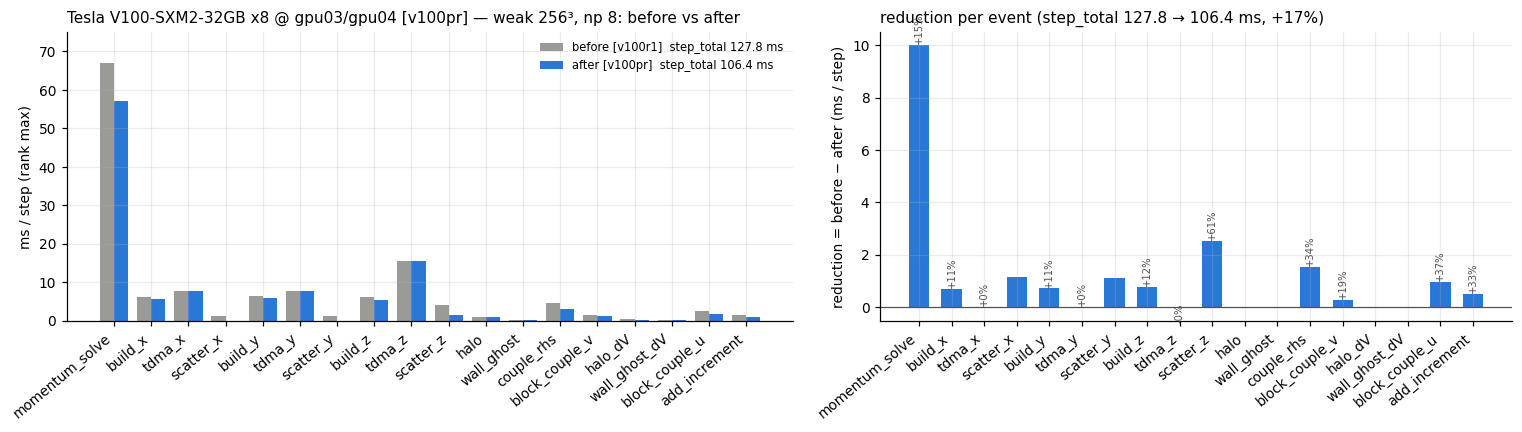

In [ ]:
BEFORE2, BEFORE2_TAG = load({'v100r1': 'v100'})
describe("before2", BEFORE2, BEFORE2_TAG)
STYLE["before2"] = STYLE["before"]
_B, _BT = BEFORE, BEFORE_TAG
BEFORE, BEFORE_TAG = BEFORE2, BEFORE2_TAG            # 아래 그림 함수들은 BEFORE 를 읽는다 — 잠시 바꿔 끼운다
for hw in ("h200", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_event_bars(BEFORE, "before2", mode, hw, n)
plt.show()
plot_scaling_section([(BEFORE, "before2"), (AFTER, "after")])
for hw in ("h200", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (4, 8):
                plot_before_after(mode, hw, n, np_)
plt.show()
COLS = [('build_x+y+z (3성분 합)', ['momentum.dU.build_x', 'momentum.dU.build_y', 'momentum.dU.build_z', 'momentum.dV.build_x', 'momentum.dV.build_y', 'momentum.dV.build_z', 'momentum.dW.build_x', 'momentum.dW.build_y', 'momentum.dW.build_z']), ('couple_rhs+block_couple', ['momentum.dV.couple_rhs', 'momentum.dW.couple_rhs', 'momentum.post.block_couple_v', 'momentum.post.block_couple_u']), ('tdma_x+y+z (3성분 합)', ['momentum.dU.tdma_x', 'momentum.dU.tdma_y', 'momentum.dU.tdma_z', 'momentum.dV.tdma_x', 'momentum.dV.tdma_y', 'momentum.dV.tdma_z', 'momentum.dW.tdma_x', 'momentum.dW.tdma_y', 'momentum.dW.tdma_z'])]
print(f"{'hw':5s} {'mode':6s} {'n':4s} {'np':3s} | {TOTAL + ' before':>22s} {'after':>8s} {'gain':>6s} | " + " | ".join(f"{lab} 전 → 후" for lab, _ in COLS))
for hw in ("h200", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                k = (hw, mode, n, np_)
                if k not in BEFORE or k not in AFTER:
                    continue
                b, a = BEFORE[k], AFTER[k]
                cells_ = " | ".join(f"{sum(b.get(e, 0) for e in keys):7.2f} → {sum(a.get(e, 0) for e in keys):7.2f} ms" for _, keys in COLS)
                print(f"{hw:5s} {mode:6s} {n:<4d} {np_:<3d} | {b[TOTAL]:22.1f} {a[TOTAL]:8.1f} {100*(1-a[TOTAL]/b[TOTAL]):5.0f}% | {cells_}")
BEFORE, BEFORE_TAG = _B, _BT

## F. 패스 제거 직전 vs 최종 — V100

전 = `v100s`, 후 = `v100p`(scatter_z 타일 전치, scatter_x/y 제거, W += 융합). 차이는 scatter_*·add_increment 에서만 나야 한다.

hw    mode   n    np  |  momentum_solve before    after   gain | scatter_x+y+z (3성분 합) 전 → 후 | add_increment 전 → 후 | build_x+y+z (3성분 합) 전 → 후
v100  strong 256  1   |                   50.5     45.8     9% |    6.32 →    1.58 ms |    1.53 →    1.03 ms |   16.20 →   16.72 ms
v100  strong 256  2   |                   27.3     25.9     5% |    2.23 →    0.83 ms |    0.78 →    0.52 ms |    7.40 →    7.57 ms
v100  strong 256  4   |                   16.7     18.7   -13% |    0.97 →    0.43 ms |    0.41 →    0.27 ms |    3.75 →    3.82 ms
v100  strong 256  8   |                   15.9     15.6     2% |    0.54 →    0.24 ms |    0.22 →    0.15 ms |    1.96 →    2.01 ms
v100  strong 512  2   |                  257.9    233.9     9% |   30.17 →    6.37 ms |    6.09 →    4.06 ms |   77.09 →   78.81 ms
v100  strong 512  4   |                  122.3    115.8     5% |    9.93 →    3.27 ms |    3.08 →    2.06 ms |   35.24 →   36.30 ms
v100  strong 512  8   |                   81.7     79.5     3% | 

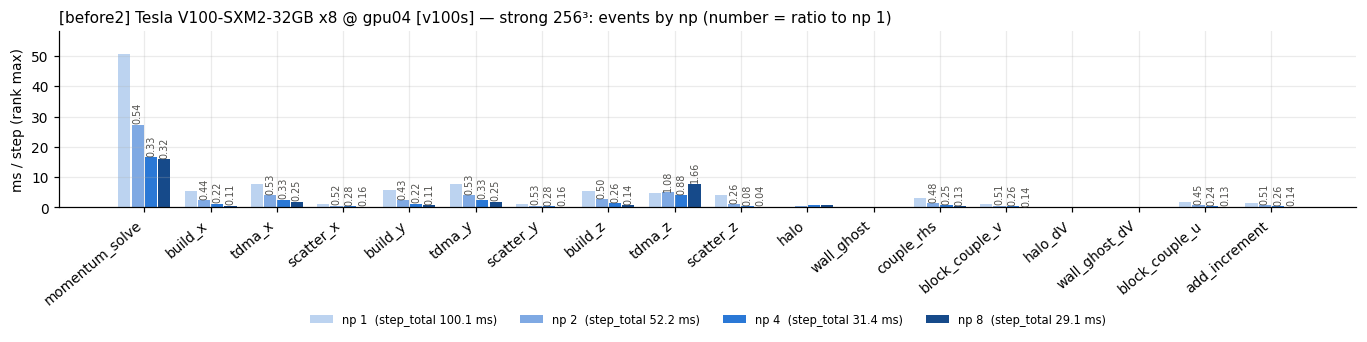

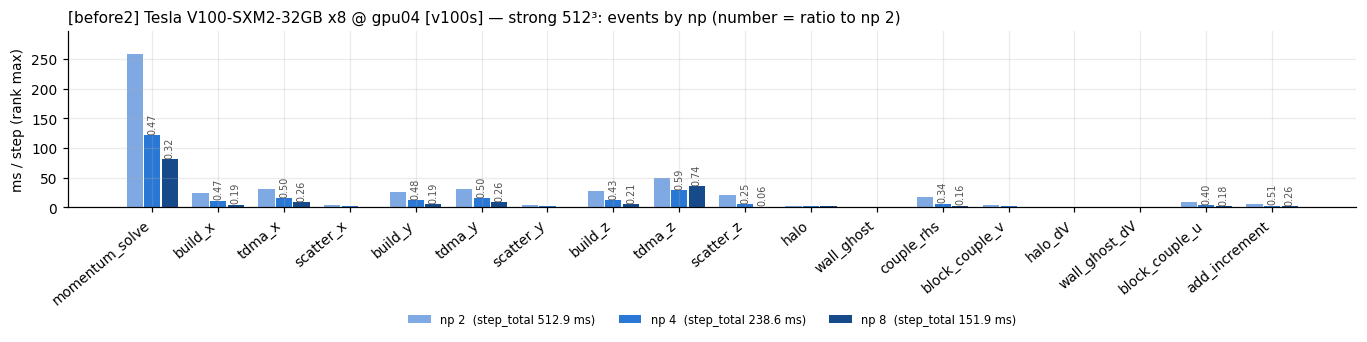

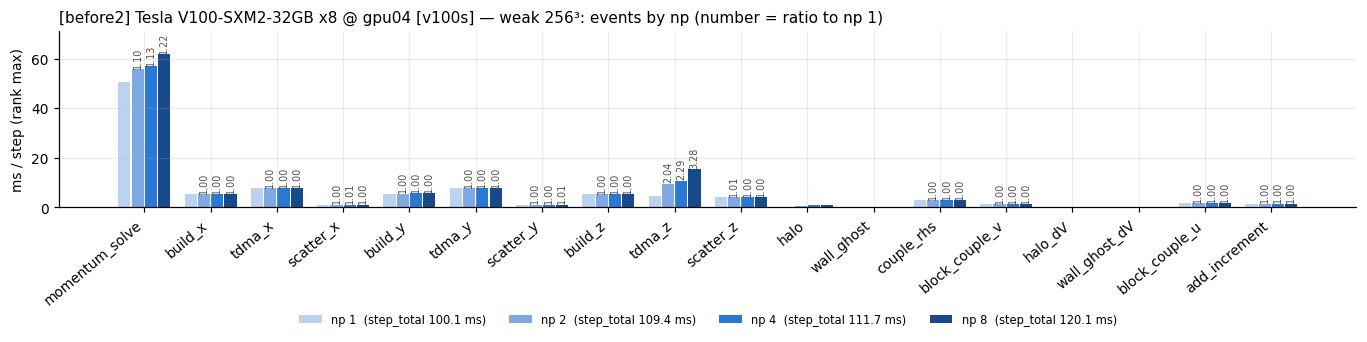

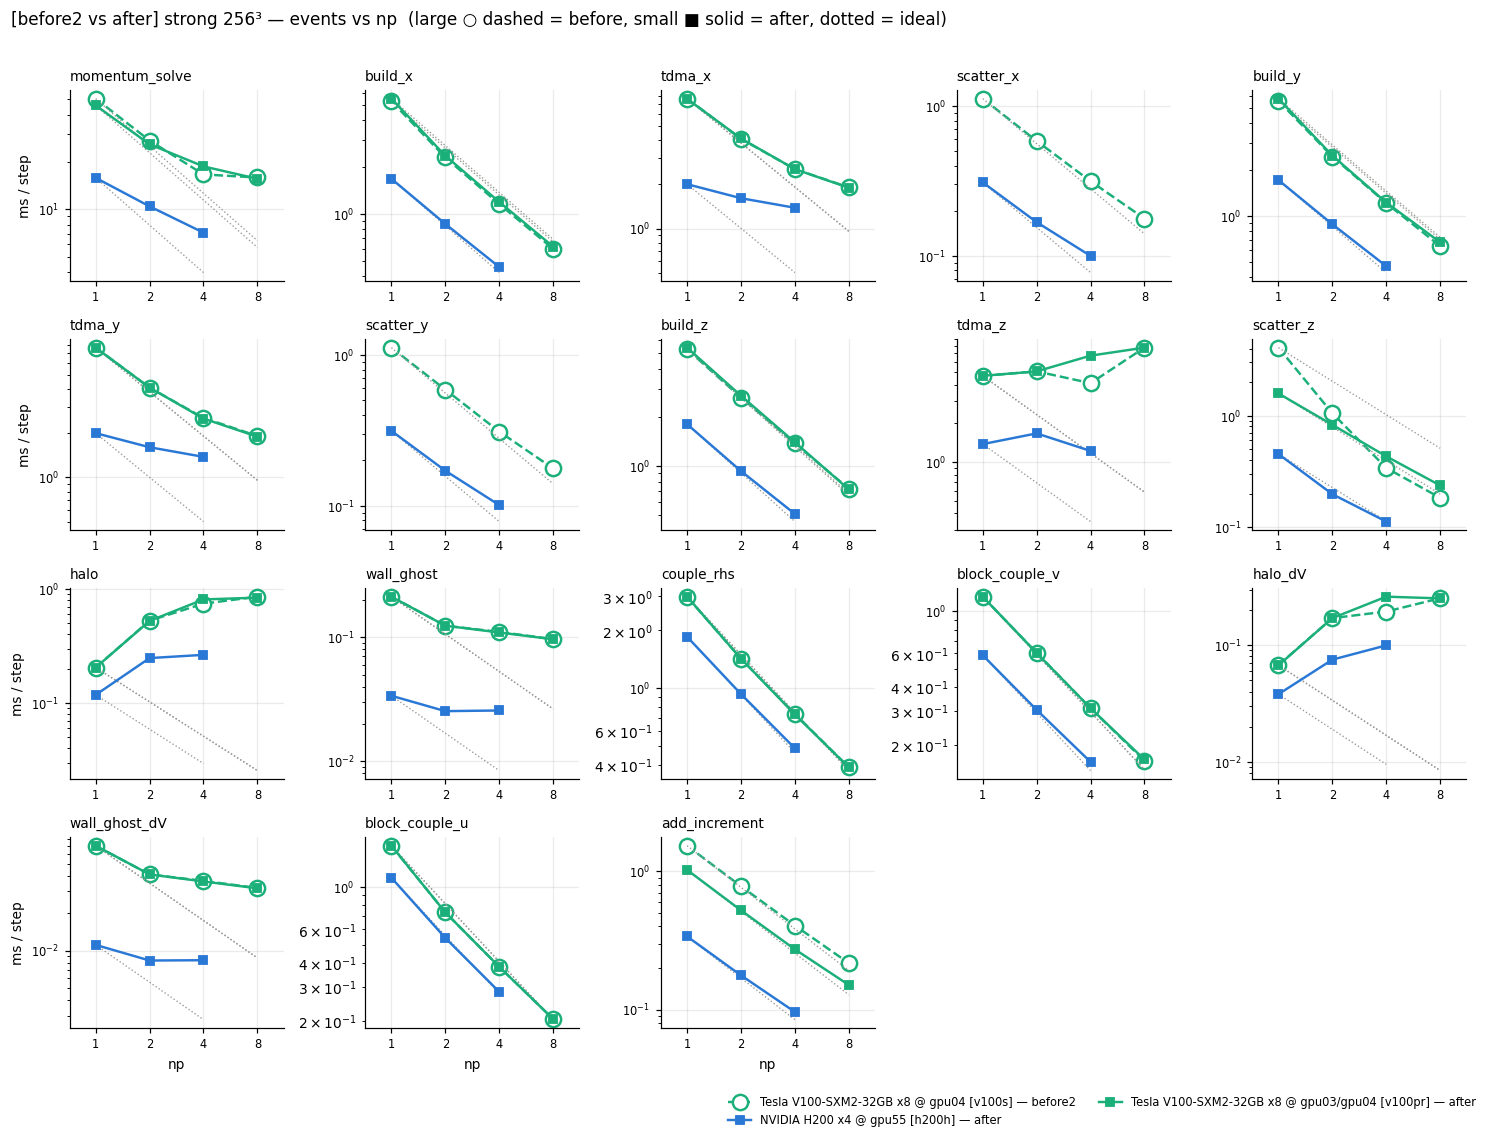

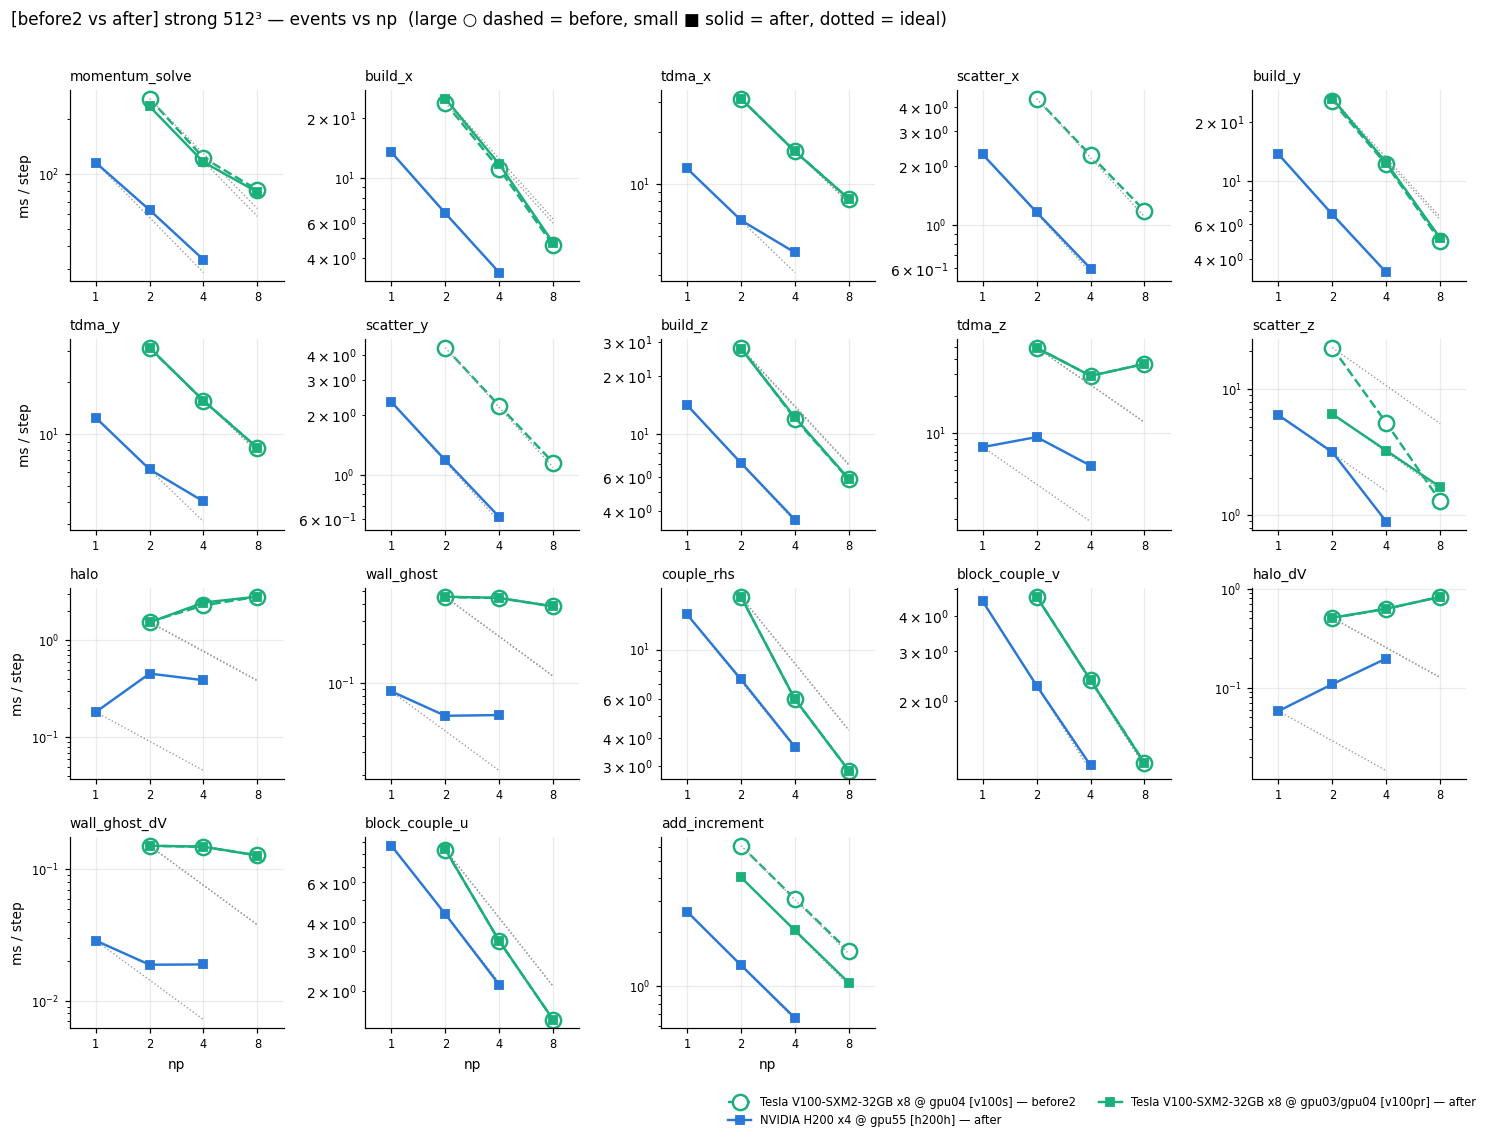

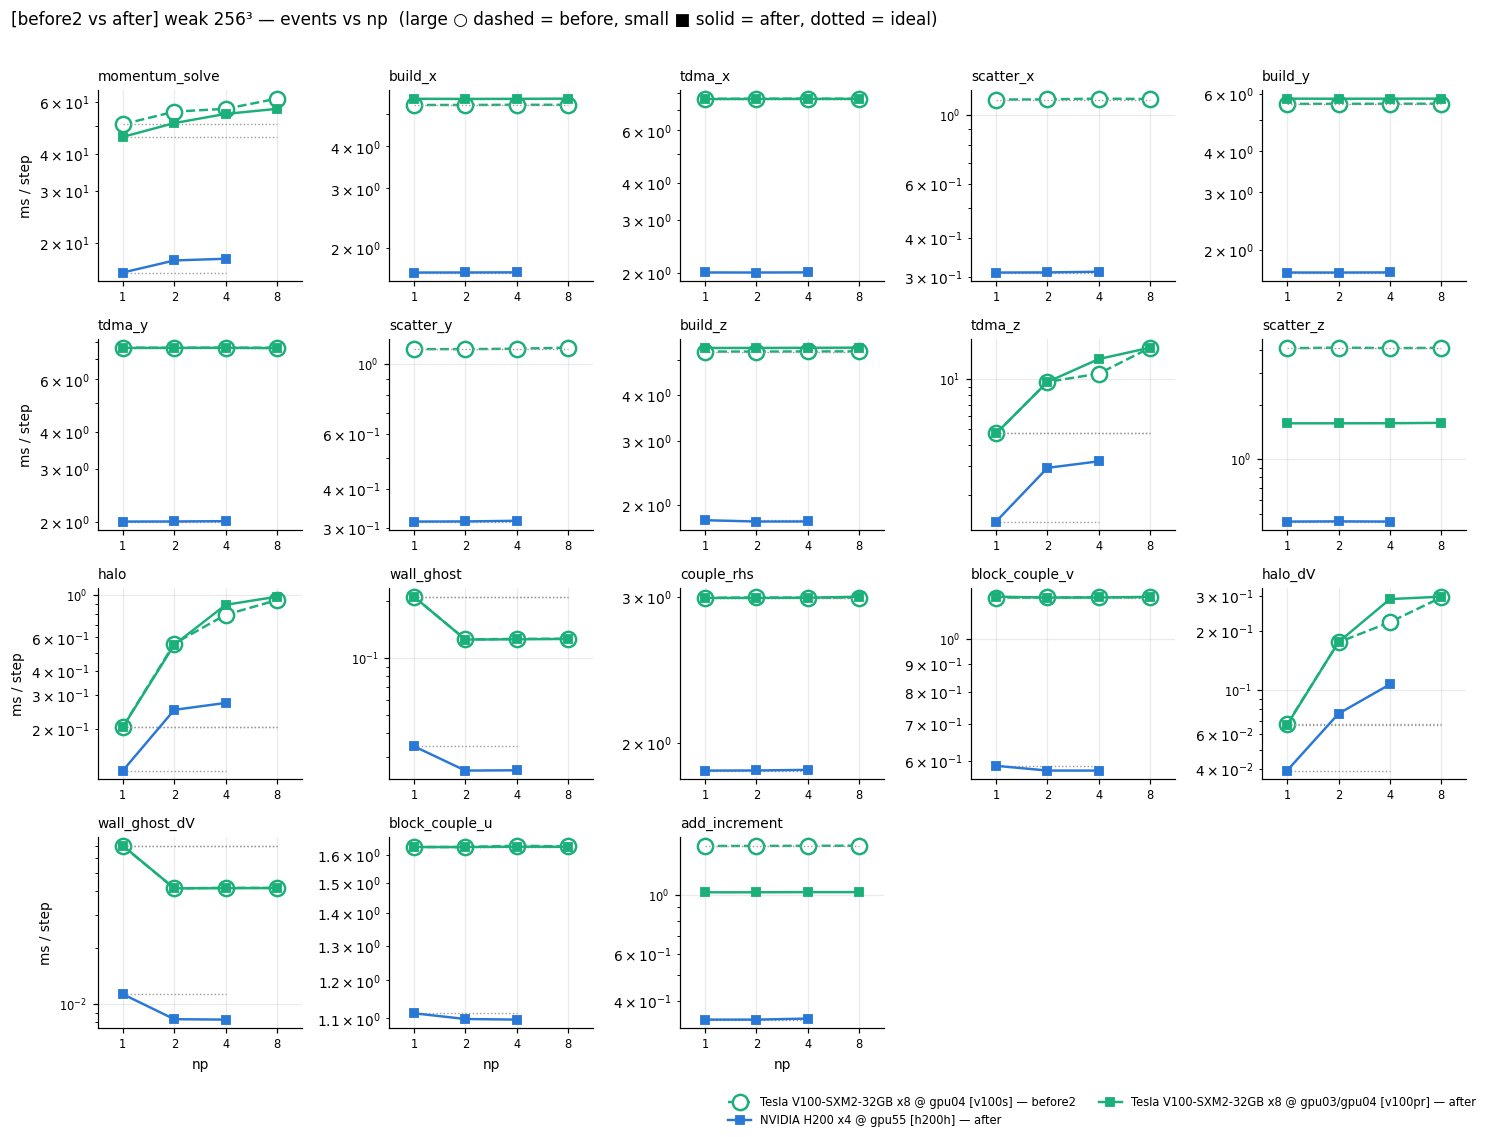

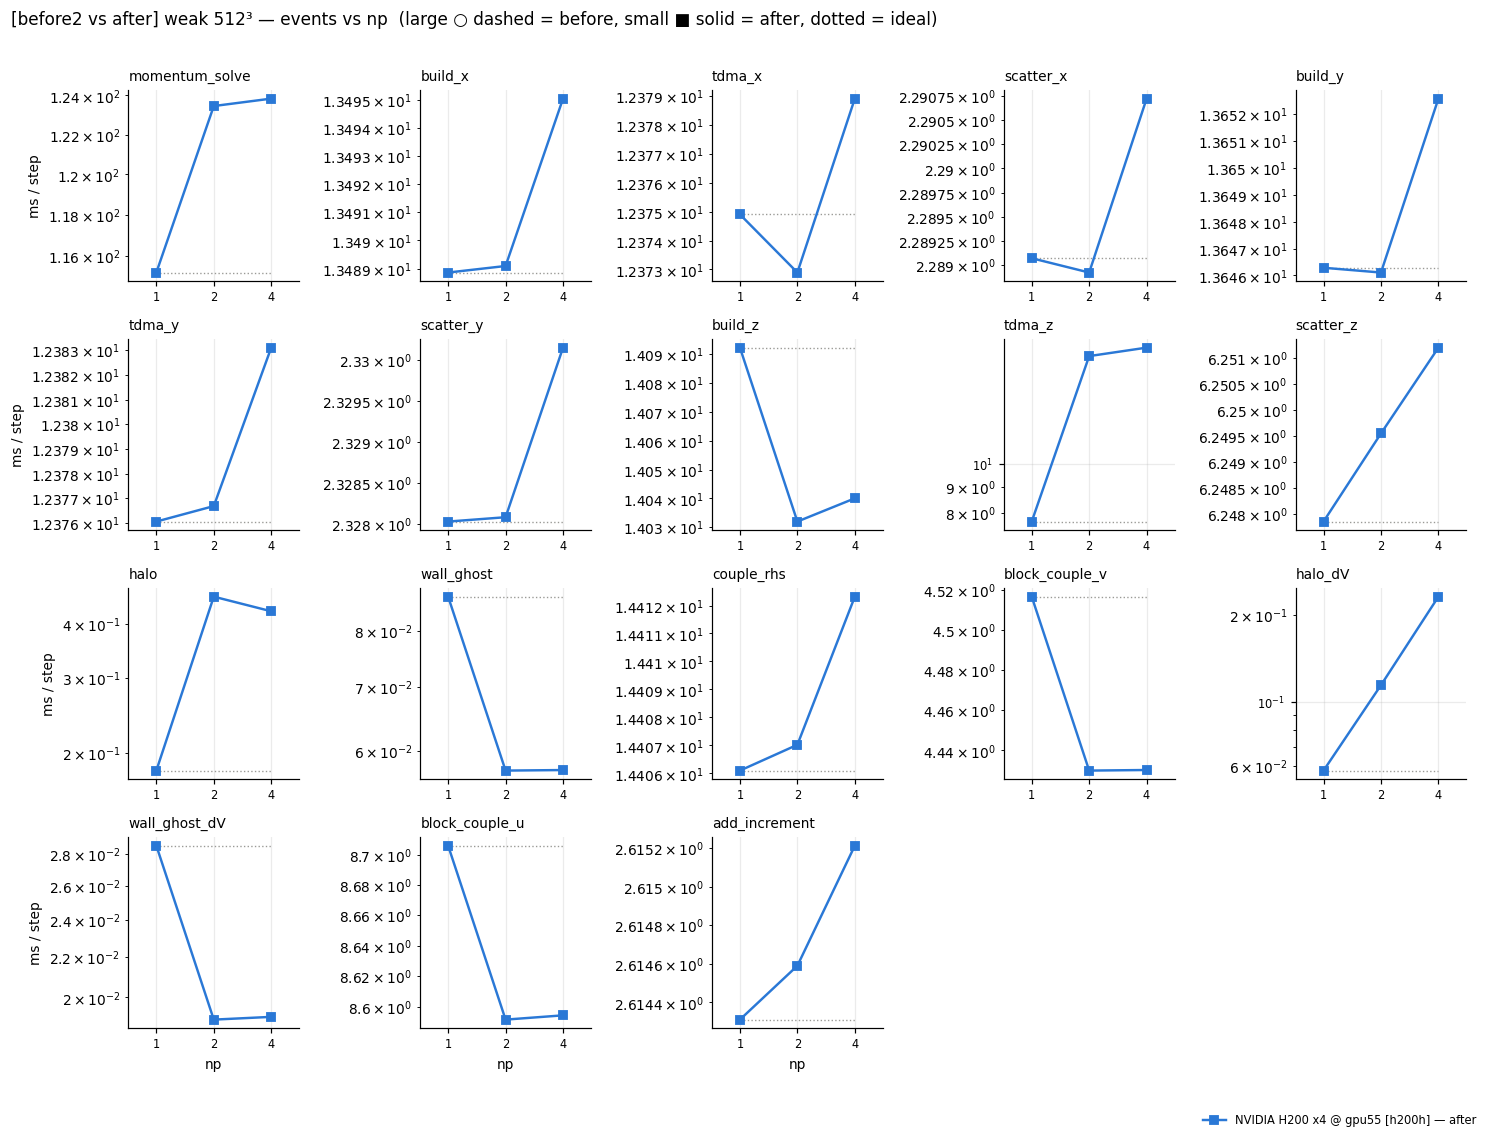

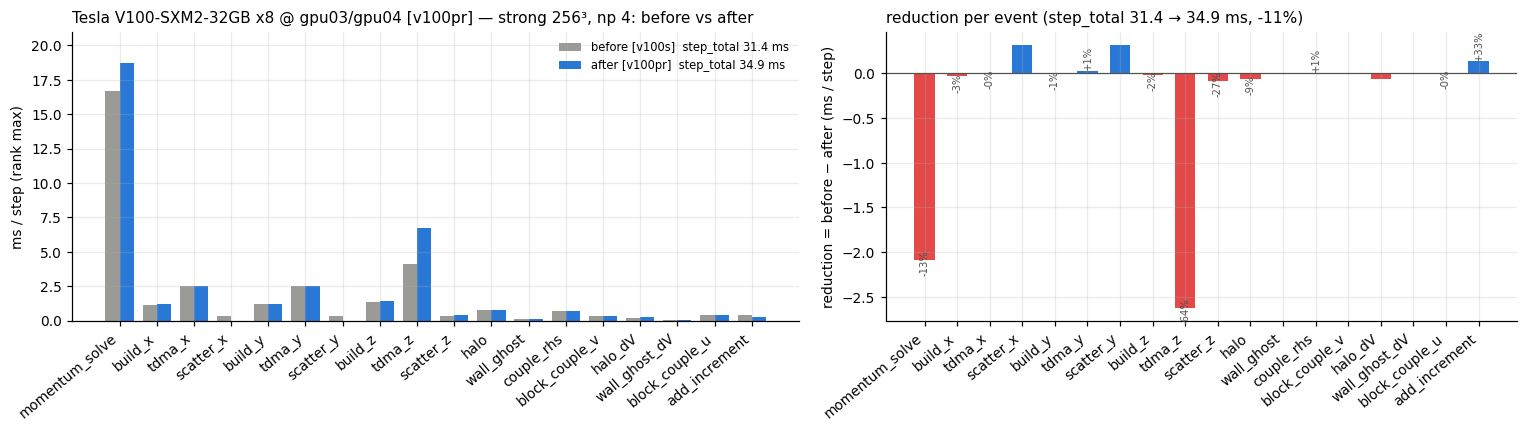

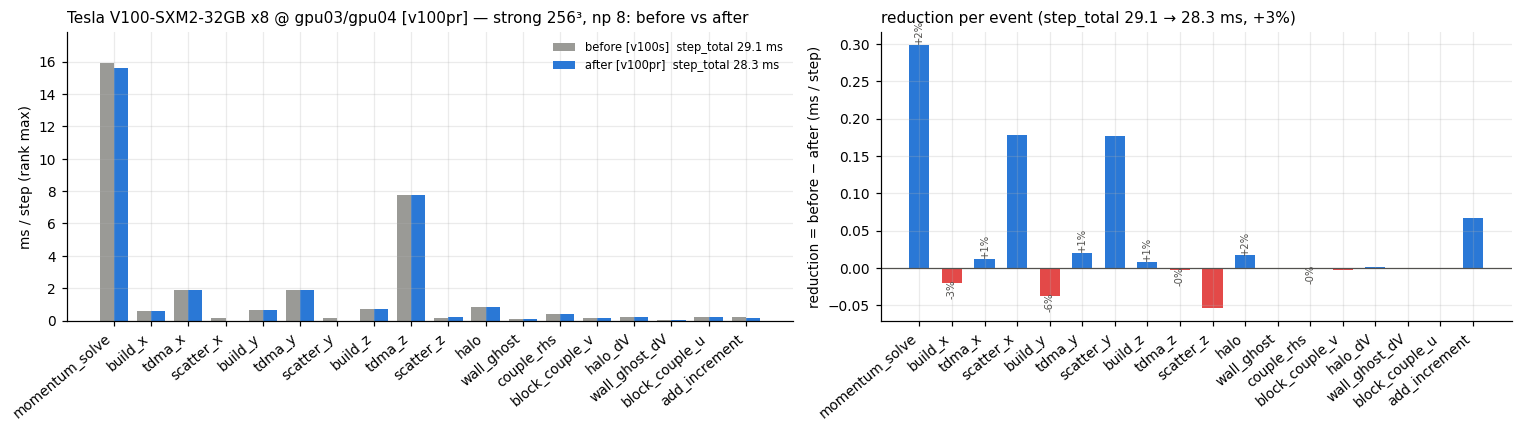

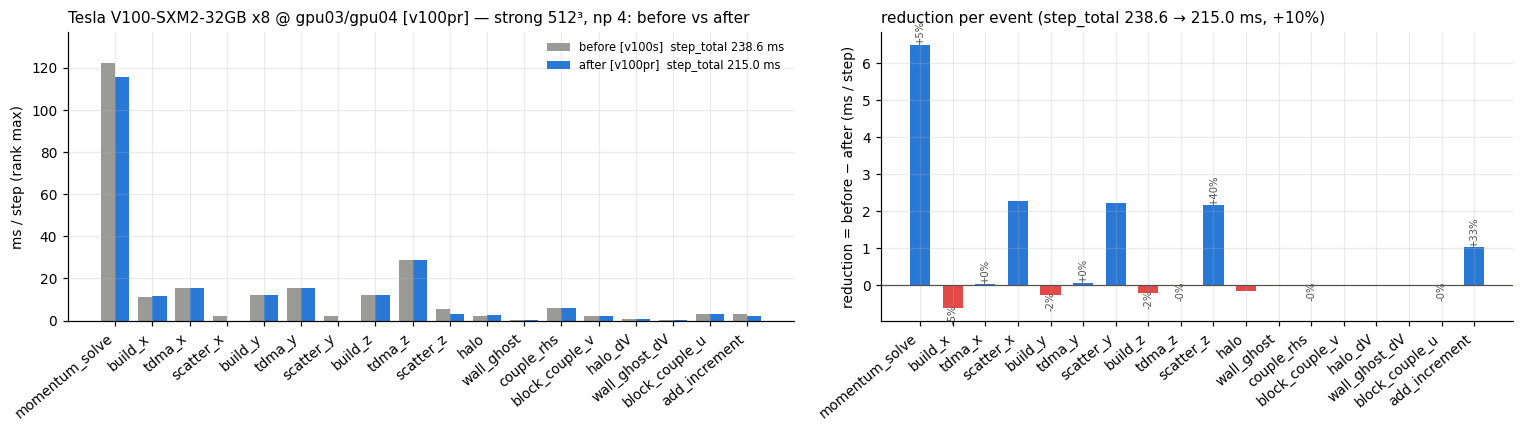

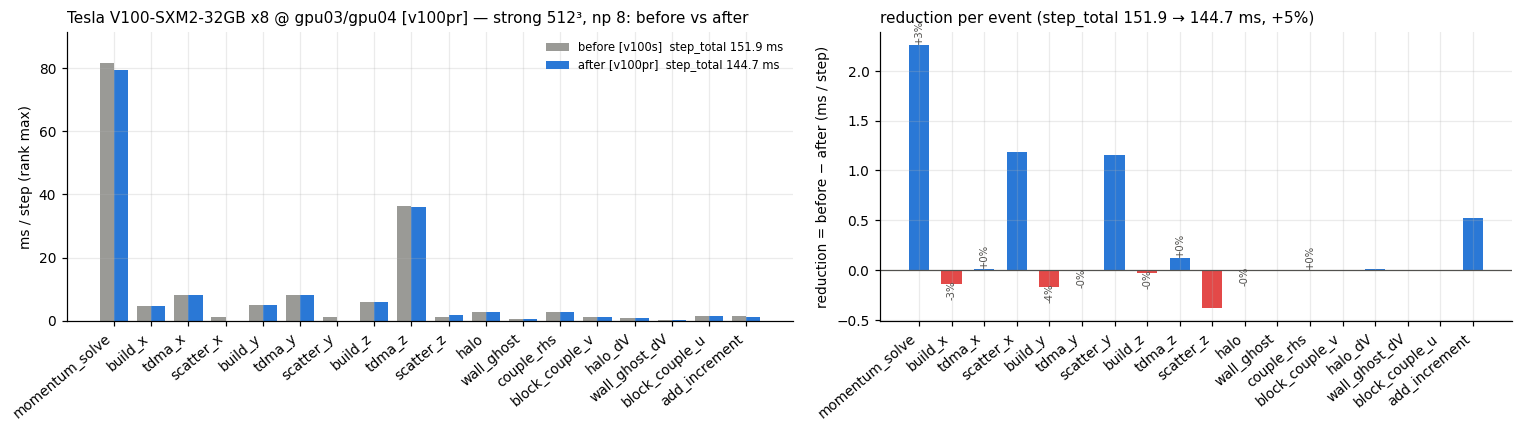

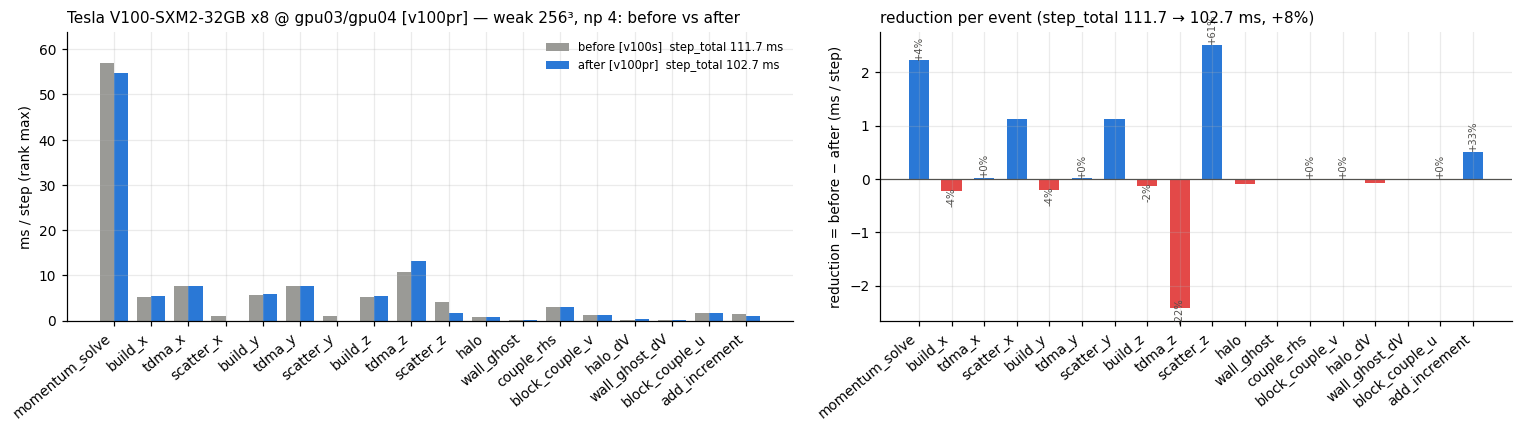

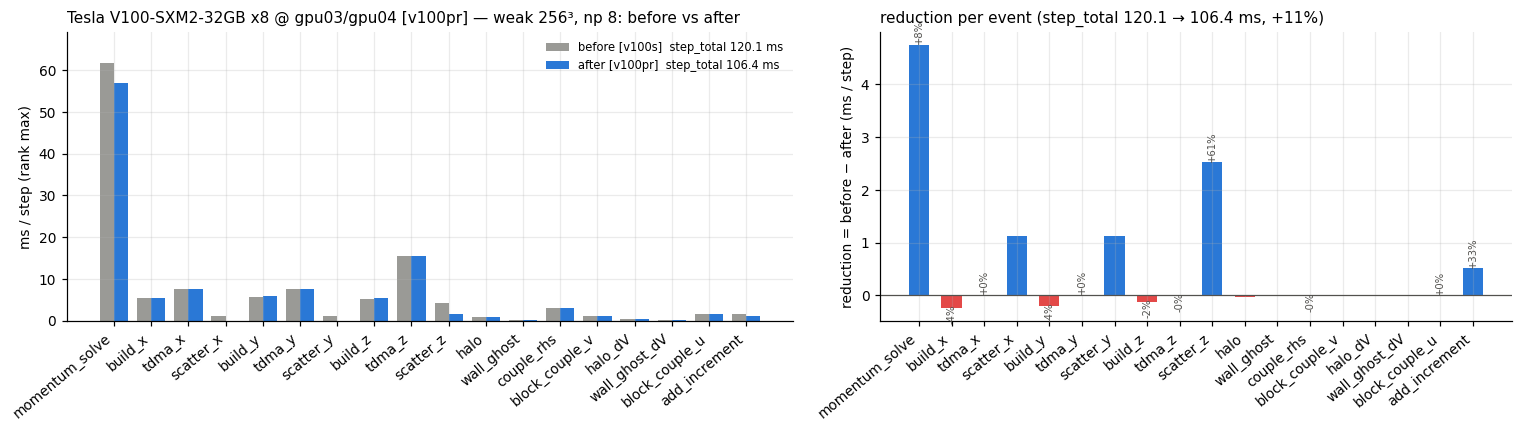

In [ ]:
BEFORE2, BEFORE2_TAG = load({'v100s': 'v100'})
describe("before2", BEFORE2, BEFORE2_TAG)
STYLE["before2"] = STYLE["before"]
_B, _BT = BEFORE, BEFORE_TAG
BEFORE, BEFORE_TAG = BEFORE2, BEFORE2_TAG            # 아래 그림 함수들은 BEFORE 를 읽는다 — 잠시 바꿔 끼운다
for hw in ("h200", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_event_bars(BEFORE, "before2", mode, hw, n)
plt.show()
plot_scaling_section([(BEFORE, "before2"), (AFTER, "after")])
for hw in ("h200", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (4, 8):
                plot_before_after(mode, hw, n, np_)
plt.show()
COLS = [('scatter_x+y+z (3성분 합)', ['momentum.dU.scatter_x', 'momentum.dU.scatter_y', 'momentum.dU.scatter_z', 'momentum.dV.scatter_x', 'momentum.dV.scatter_y', 'momentum.dV.scatter_z', 'momentum.dW.scatter_x', 'momentum.dW.scatter_y', 'momentum.dW.scatter_z']), ('add_increment', ['momentum.post.add_increment']), ('build_x+y+z (3성분 합)', ['momentum.dU.build_x', 'momentum.dU.build_y', 'momentum.dU.build_z', 'momentum.dV.build_x', 'momentum.dV.build_y', 'momentum.dV.build_z', 'momentum.dW.build_x', 'momentum.dW.build_y', 'momentum.dW.build_z'])]
print(f"{'hw':5s} {'mode':6s} {'n':4s} {'np':3s} | {TOTAL + ' before':>22s} {'after':>8s} {'gain':>6s} | " + " | ".join(f"{lab} 전 → 후" for lab, _ in COLS))
for hw in ("h200", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                k = (hw, mode, n, np_)
                if k not in BEFORE or k not in AFTER:
                    continue
                b, a = BEFORE[k], AFTER[k]
                cells_ = " | ".join(f"{sum(b.get(e, 0) for e in keys):7.2f} → {sum(a.get(e, 0) for e in keys):7.2f} ms" for _, keys in COLS)
                print(f"{hw:5s} {mode:6s} {n:<4d} {np_:<3d} | {b[TOTAL]:22.1f} {a[TOTAL]:8.1f} {100*(1-a[TOTAL]/b[TOTAL]):5.0f}% | {cells_}")
BEFORE, BEFORE_TAG = _B, _BT